In [ ]:
import pandas as pd

df = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df['Tahun'] = df['Tahun'].ffill()
df['Tahun'] = df['Tahun'].astype(int)

df

In [2]:
df.dtypes

Tahun          int64
Bulan         object
Bulanan      float64
Kumulatif    float64
YoY           object
dtype: object

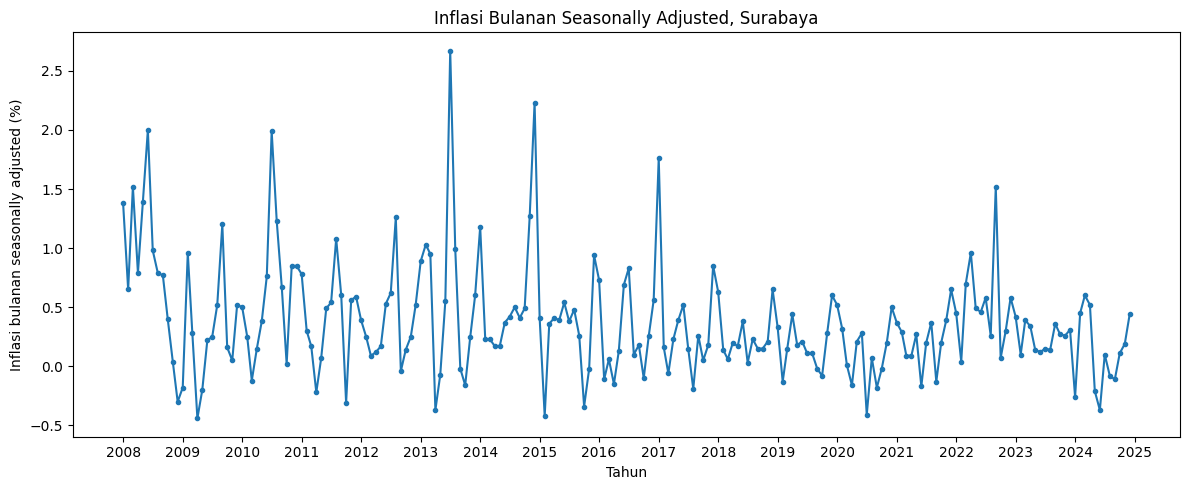

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

tahun = pd.to_numeric(df['Tahun'], errors='raise').astype(int)
bulan = df['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)

if bulan.isna().any():
    raise ValueError(f"Unrecognized month names: {df.loc[bulan.isna(), 'Bulan'].unique()}")

df_plot = df.copy()
df_plot['Tanggal'] = pd.to_datetime({
    'year': tahun,
    'month': bulan,
    'day': 1
})
df_plot = df_plot.sort_values('Tanggal')

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_plot['Tanggal'], df_plot['Bulanan'], marker='o', markersize=3)

ax.set_xlabel('Tahun')
ax.set_ylabel('Inflasi bulanan seasonally adjusted (%)')
ax.set_title('Inflasi Bulanan Seasonally Adjusted, Surabaya')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
plt.show()

## Uji Stationeritas Gabungan ADF, KPSS, dan Zivot-Andrews

In [ ]:
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews

def diagnosa_konflik(series, nama='Data'):
    print(f"\n{'='*55}\n  DIAGNOSA KONFLIK ADF vs KPSS: {nama}\n{'='*55}")
    print(f"n observasi = {len(series)}")
    if len(series) < 30:
        print("⚠️  n < 30: hasil uji TIDAK reliable secara statistik.")
    
    for reg in ['c', 'ct']:
        p_adf  = adfuller(series, regression=reg, autolag='AIC')[1]
        p_kpss = kpss(series, regression=reg, nlags='auto')[1]
        print(f"\n[{reg}] ADF p={p_adf:.4f} | KPSS p={p_kpss:.4f}")
        if p_adf < 0.05 and p_kpss >= 0.05:
            print("  ✅ KONSISTEN: Stasioner")
        elif p_adf >= 0.05 and p_kpss < 0.05:
            print("  ❌ KONSISTEN: Tidak stasioner")
        else:
            print("  ⚠️  KONFLIK → cek structural break (Zivot-Andrews)")

    za_stat, za_p, _, _, _ = zivot_andrews(series, regression='c')
    print(f"\nZivot-Andrews: stat={za_stat:.4f}, p={za_p:.4f}")
    if za_p < 0.05:
        print("  ✅ Stasioner dengan izin structural break")

diagnosa_konflik(df['Bulanan'].dropna(), 'Inflasi Bulanan 2008')


  DIAGNOSA KONFLIK ADF vs KPSS: Inflasi Bulanan 2008
n observasi = 204

[c] ADF p=0.0011 | KPSS p=0.0100
  ⚠️  KONFLIK → cek structural break (Zivot-Andrews)

[ct] ADF p=0.0009 | KPSS p=0.1000
  ✅ KONSISTEN: Stasioner

Zivot-Andrews: stat=-5.2770, p=0.0100
  ✅ Stasioner dengan izin structural break


C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\1360438827.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_adf  = adfuller(series, regression=reg, autolag='AIC')[1]
C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\1360438827.py:9: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  p_kpss = kpss(series, regression=reg, nlags='auto')[1]
C:\Users\Sulaiman\AppData\Local\Temp\ipykernel_36396\1360438827.py:9: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when stor

In [8]:
import pmdarima as pm

# Menjalankan auto_arima dengan musiman 12 bulan
# d=0 karena uji stasioneritas sebelumnya sudah konfirmasi stasioner
stepwise_model = pm.auto_arima(
    series,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=0,              # Sesuaikan jika Anda ingin mencoba differencing (d=1)
    seasonal=True,
    m=12,             # Musiman 12 bulan (Surabaya inflation seasonality)
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,           # Biarkan auto_arima mendeteksi seasonal differencing (D)
    information_criterion='bic', # Pilih 'bic' atau 'aic'
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True
)

print("\n==========================================")
print("  MODEL SARIMA TERBAIK (BERDASARKAN BIC)")
print("==========================================")
print(stepwise_model.summary())

Performing stepwise search to minimize bic
 ARIMA(0,0,0)(0,0,0)[12] intercept   : BIC=282.934, Time=0.05 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : BIC=252.970, Time=0.10 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : BIC=250.971, Time=0.08 sec
 ARIMA(0,0,0)(0,0,0)[12]             : BIC=376.548, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[12] intercept   : BIC=250.547, Time=0.03 sec
 ARIMA(0,0,1)(1,0,0)[12] intercept   : BIC=250.578, Time=0.11 sec
 ARIMA(0,0,1)(1,0,1)[12] intercept   : BIC=248.833, Time=0.27 sec
 ARIMA(0,0,1)(2,0,1)[12] intercept   : BIC=253.800, Time=0.45 sec
 ARIMA(0,0,1)(1,0,2)[12] intercept   : BIC=253.413, Time=0.47 sec
 ARIMA(0,0,1)(0,0,2)[12] intercept   : BIC=256.289, Time=0.17 sec
 ARIMA(0,0,1)(2,0,0)[12] intercept   : BIC=254.879, Time=0.31 sec
 ARIMA(0,0,1)(2,0,2)[12] intercept   : BIC=inf, Time=0.78 sec
 ARIMA(0,0,0)(1,0,1)[12] intercept   : BIC=271.663, Time=0.15 sec
 ARIMA(1,0,1)(1,0,1)[12] intercept   : BIC=253.669, Time=0.21 sec
 ARIMA(0,0,2)(1,0,1)[12] intercept   

## Uji Autokorelasi (ljungbox) dan Normalitas (Jarque-Bera)

=== UJI LJUNG-BOX RESIDUAL ===
      lb_stat  lb_pvalue
12  14.882887   0.247904
24  26.980585   0.305359
(Catatan: P-value > 0.05 menunjukkan residual bersifat white noise / aman)

=== UJI JARQUE-BERA NORMALITAS ===
JB Statistic = 258.3543, p-value = 0.0000



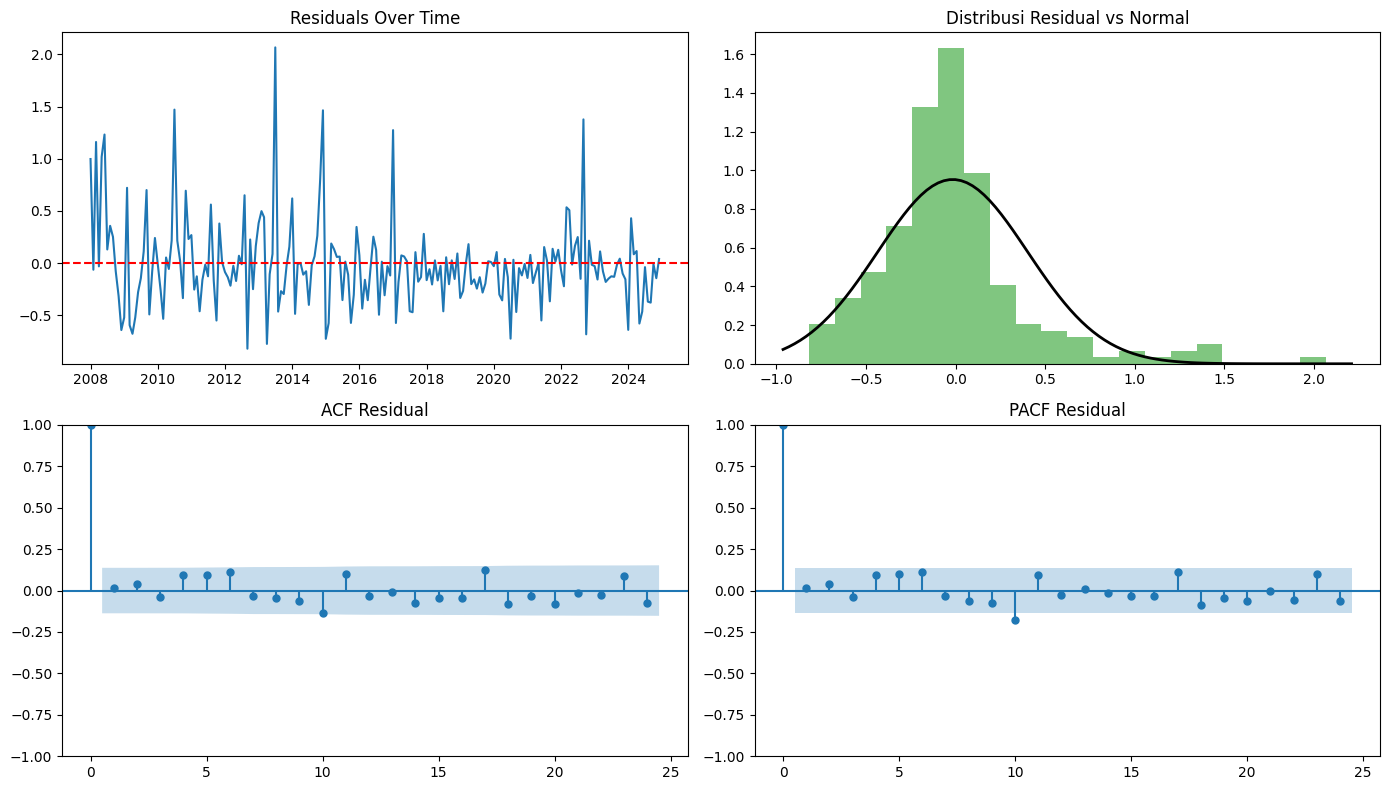

In [11]:
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
import numpy as np

# Mengambil residual dari model optimal
residuals = stepwise_model.resid()

# 1. Uji Ljung-Box untuk Autokorelasi Residual (pada lag 12 dan 24)
lb_test = sm.stats.acorr_ljungbox(residuals, lags=[12, 24], return_df=True)
print("=== UJI LJUNG-BOX RESIDUAL ===")
print(lb_test)
print("(Catatan: P-value > 0.05 menunjukkan residual bersifat white noise / aman)\n")

# 2. Uji Normalitas Jarque-Bera
jb_stat, jb_pvalue = stats.jarque_bera(residuals)
print(f"=== UJI JARQUE-BERA NORMALITAS ===")
print(f"JB Statistic = {jb_stat:.4f}, p-value = {jb_pvalue:.4f}\n")

# 3. Plot Diagnostik Residual
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(residuals, color='tab:blue')
axes[0, 0].set_title("Residuals Over Time")
axes[0, 0].axhline(0, color='red', linestyle='--')

axes[0, 1].hist(residuals, bins=20, density=True, alpha=0.6, color='tab:green')
xmin, xmax = axes[0, 1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, np.mean(residuals), np.std(residuals))
axes[0, 1].plot(x, p, 'k', linewidth=2)
axes[0, 1].set_title("Distribusi Residual vs Normal")

sm.graphics.tsa.plot_acf(residuals, lags=24, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title("ACF Residual")

sm.graphics.tsa.plot_pacf(residuals, lags=24, ax=axes[1, 1], method='yw', alpha=0.05)
axes[1, 1].set_title("PACF Residual")

plt.tight_layout()
plt.show()

mencoba explore sarima

Training set: 180 observasi | Testing set: 24 observasi

=== EVALUASI OUT-OF-SAMPLE (24 BULAN TERAKHIR) ===
RMSE : 0.2650
MAE  : 0.1945


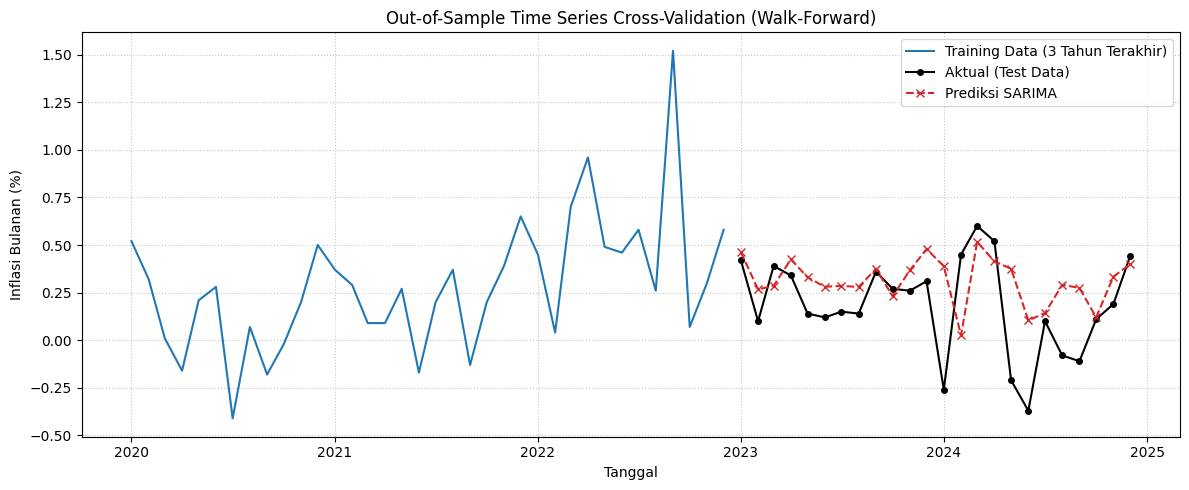

In [12]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Tentukan jumlah data testing di akhir (misal 24 bulan / 2 tahun terakhir)
n_test = 24
train = series.iloc[:-n_test]
test = series.iloc[-n_test:]

history = list(train)
predictions = []

print(f"Training set: {len(train)} observasi | Testing set: {len(test)} observasi")

# Walk-forward validation loop
for t in range(len(test)):
    # Fit ulang model dengan parameter order & seasonal_order terbaik dari auto_arima
    model = pm.ARIMA(order=stepwise_model.order, seasonal_order=stepwise_model.seasonal_order)
    fitted_model = model.fit(history)
    
    # Prediksi 1 langkah ke depan
    yhat = fitted_model.predict(n_periods=1)[0]
    predictions.append(yhat)
    
    # Masukkan nilai aktual ke history untuk iterasi berikutnya
    obs = test.iloc[t]
    history.append(obs)

predictions = pd.Series(predictions, index=test.index)

# Hitung Metrik Evaluasi Out-of-Sample
rmse = root_mean_squared_error(test, predictions)
mae = mean_absolute_error(test, predictions)

print(f"\n=== EVALUASI OUT-OF-SAMPLE (24 BULAN TERAKHIR) ===")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")

# Visualisasi Hasil Prediksi vs Aktual
plt.figure(figsize=(12, 5))
plt.plot(train.index[-36:], train.iloc[-36:], label="Training Data (3 Tahun Terakhir)", color='tab:blue')
plt.plot(test.index, test, label="Aktual (Test Data)", color="black", marker='o', markersize=4)
plt.plot(predictions.index, predictions, label="Prediksi SARIMA", color="tab:red", linestyle='--', marker='x')
plt.title("Out-of-Sample Time Series Cross-Validation (Walk-Forward)")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

simulasi jika data semua normal

Total observations loaded: 204

--- Running Auto-ARIMA Grid Search ---
Performing stepwise search to minimize bic
 ARIMA(0,1,0)(0,0,0)[12] intercept   : BIC=466.941, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : BIC=435.456, Time=0.06 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : BIC=460.077, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[12]             : BIC=461.775, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : BIC=472.087, Time=0.01 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : BIC=417.374, Time=0.15 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : BIC=inf, Time=0.62 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : BIC=inf, Time=0.38 sec
 ARIMA(0,1,0)(2,0,0)[12] intercept   : BIC=449.599, Time=0.10 sec
 ARIMA(2,1,0)(2,0,0)[12] intercept   : BIC=inf, Time=0.25 sec
 ARIMA(1,1,1)(2,0,0)[12] intercept   : BIC=inf, Time=0.65 sec
 ARIMA(0,1,1)(2,0,0)[12] intercept   : BIC=inf, Time=0.61 sec
 ARIMA(2,1,1)(2,0,0)[12] intercept   : BIC=368.910, Time=0.75 sec
 ARIMA(2,1,1)(1,0,0)[12] intercept   : BIC=inf, 

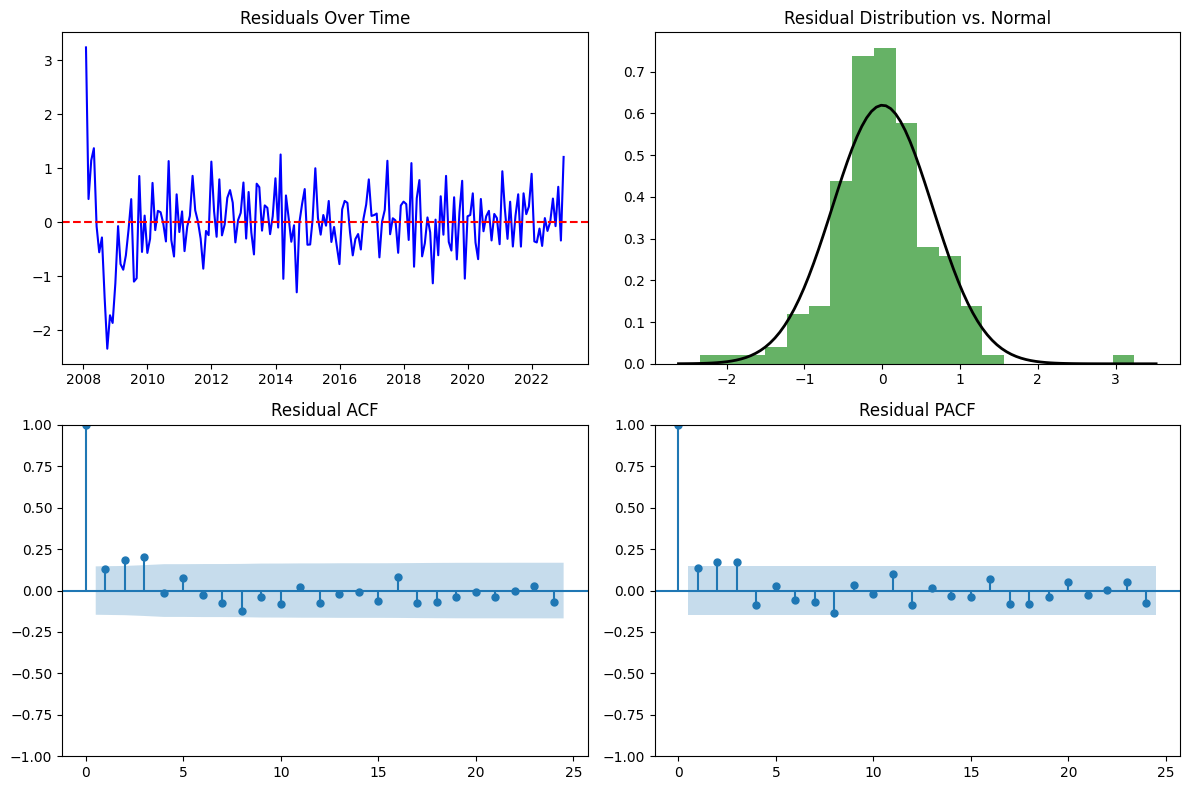


--- Running Out-of-Sample Time Series Cross-Validation ---
Training set size: 180, Testing set size: 24

Out-of-Sample Evaluation Metrics (Last 24 Months):
RMSE : 0.3496
MAE  : 0.2797


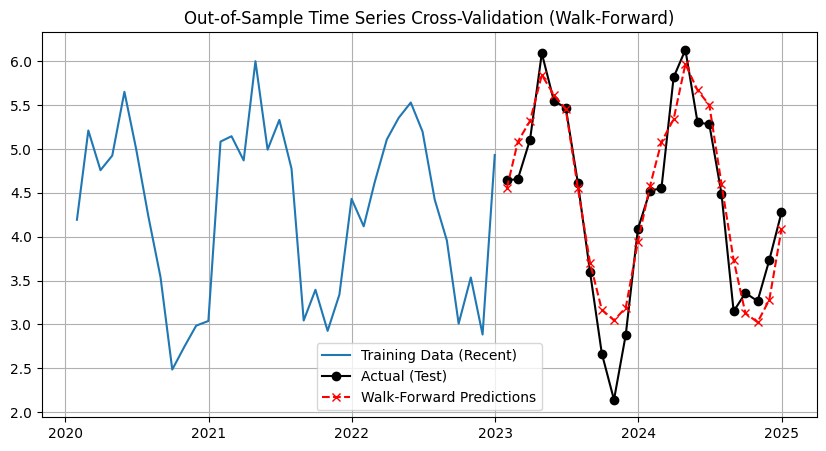

In [2]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima import auto_arima
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 0. Mock Data Setup (Replace with your df['inflation'])
# ==========================================
# Simulating monthly data from Jan 2008 to Dec 2024 (N = 204)
dates = pd.date_range(start="2008-01-01", end="2024-12-31", freq="ME")
np.random.seed(42)
# Creating a dummy seasonal stationary inflation series around 3-5%
trend = np.linspace(3, 4.5, len(dates))
seasonality = 1.5 * np.sin(2 * np.pi * np.arange(len(dates)) / 12)
noise = np.random.normal(0, 0.5, len(dates))
inflation_series = pd.Series(trend + seasonality + noise, index=dates)

print(f"Total observations loaded: {len(inflation_series)}")

# Keep the holdout out of model selection and fitting
n_test = 24
train = inflation_series.iloc[:-n_test]
test = inflation_series.iloc[-n_test:]

# ==========================================
# PART 1: Automated Grid Search (AIC / BIC)
# ==========================================
print("\n--- Running Auto-ARIMA Grid Search ---")

# auto_arima explores combinations of p, q, P, Q minimizing AIC (or BIC)
# d=0 or d=1 based on your prior stationarity check. Setting seasonal=True, m=12.
auto_model = auto_arima(
    train,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,          # Let auto_arima test stationarity (or set to 0 if already stationary)
    seasonal=True,
    m=12,            # 12-month seasonality
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,          # Seasonal differencing
    information_criterion='bic', # Use 'bic' for parsimonious macroeconomic models, or 'aic'
    stepwise=True,   # Fast stepwise search algorithm
    suppress_warnings=True,
    error_action="ignore",
    trace=True
)

print("\nOptimal Model Summary:")
print(auto_model.summary())

# ==========================================
# PART 2: Comprehensive Residual Diagnostics
# ==========================================
print("\n--- Running Residual Diagnostics ---")

residuals = auto_model.resid()

# 1. Ljung-Box Test for Autocorrelation (checking up to lag 24)
lb_test = sm.stats.acorr_ljungbox(residuals, lags=[12, 24], return_df=True)
print("\nLjung-Box Test Results:")
print(lb_test)
# Interpretation: p-value > 0.05 indicates white noise residuals (no remaining autocorrelation).

# 2. Normality Test (Jarque-Bera)
jb_stat, jb_pvalue = stats.jarque_bera(residuals)
print(f"\nJarque-Bera Normality Test: Stat = {jb_stat:.4f}, p-value = {jb_pvalue:.4f}")

# 3. Diagnostic Plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Standardized residuals plot
axes[0, 0].plot(residuals, color='b')
axes[0, 0].set_title("Residuals Over Time")
axes[0, 0].axhline(0, color='red', linestyle='--')

# Histogram & KDE vs Normal Distribution
axes[0, 1].hist(residuals, bins=20, density=True, alpha=0.6, color='g')
xmin, xmax = axes[0, 1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, np.mean(residuals), np.std(residuals))
axes[0, 1].plot(x, p, 'k', linewidth=2)
axes[0, 1].set_title("Residual Distribution vs. Normal")

# ACF & PACF of Residuals
sm.graphics.tsa.plot_acf(residuals, lags=24, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title("Residual ACF")

sm.graphics.tsa.plot_pacf(residuals, lags=24, ax=axes[1, 1], method='yw', alpha=0.05)
axes[1, 1].set_title("Residual PACF")

plt.tight_layout()
plt.show()

# ==========================================
# PART 3: Out-of-Sample Time Series Cross-Validation
# (Walk-Forward / Rolling-Origin Validation)
# ==========================================
print("\n--- Running Out-of-Sample Time Series Cross-Validation ---")

predictions = []

print(f"Training set size: {len(train)}, Testing set size: {len(test)}")

# Reuse the training fit and append actuals without re-estimating parameters
results = auto_model.arima_res_
for date, obs in test.items():
    yhat = results.forecast(steps=1).iloc[0]
    predictions.append(yhat)
    results = results.append(pd.Series([obs], index=[date]), refit=False)

predictions = pd.Series(predictions, index=test.index)

# Compute Error Metrics
rmse = root_mean_squared_error(test, predictions)
mae = mean_absolute_error(test, predictions)

print(f"\nOut-of-Sample Evaluation Metrics (Last {n_test} Months):")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")

# Plot Actual vs Predicted Out-of-Sample
plt.figure(figsize=(10, 5))
plt.plot(train.index[-36:], train.iloc[-36:], label="Training Data (Recent)")
plt.plot(test.index, test, label="Actual (Test)", color="black", marker='o')
plt.plot(predictions.index, predictions, label="Walk-Forward Predictions", color="red", linestyle='--', marker='x')
plt.title("Out-of-Sample Time Series Cross-Validation (Walk-Forward)")
plt.legend()
plt.grid(True)
plt.show()

Total observations loaded: 204


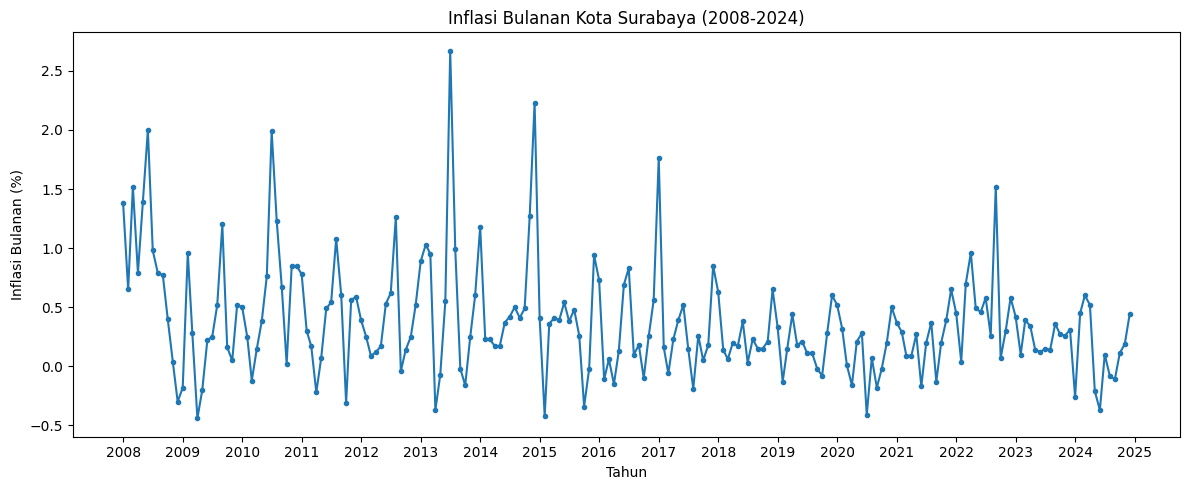


--- Running Auto-ARIMA Grid Search ---
Performing stepwise search to minimize bic
 ARIMA(0,0,0)(0,0,0)[12] intercept   : BIC=282.934, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : BIC=252.970, Time=0.09 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : BIC=250.971, Time=0.07 sec
 ARIMA(0,0,0)(0,0,0)[12]             : BIC=376.548, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[12] intercept   : BIC=250.547, Time=0.02 sec
 ARIMA(0,0,1)(1,0,0)[12] intercept   : BIC=250.578, Time=0.08 sec
 ARIMA(0,0,1)(1,0,1)[12] intercept   : BIC=248.833, Time=0.20 sec
 ARIMA(0,0,1)(2,0,1)[12] intercept   : BIC=253.800, Time=0.38 sec
 ARIMA(0,0,1)(1,0,2)[12] intercept   : BIC=253.413, Time=0.48 sec
 ARIMA(0,0,1)(0,0,2)[12] intercept   : BIC=256.289, Time=0.17 sec
 ARIMA(0,0,1)(2,0,0)[12] intercept   : BIC=254.879, Time=0.29 sec
 ARIMA(0,0,1)(2,0,2)[12] intercept   : BIC=inf, Time=0.77 sec
 ARIMA(0,0,0)(1,0,1)[12] intercept   : BIC=271.663, Time=0.13 sec
 ARIMA(1,0,1)(1,0,1)[12] intercept   : BIC=253.669, Time=0.20 s

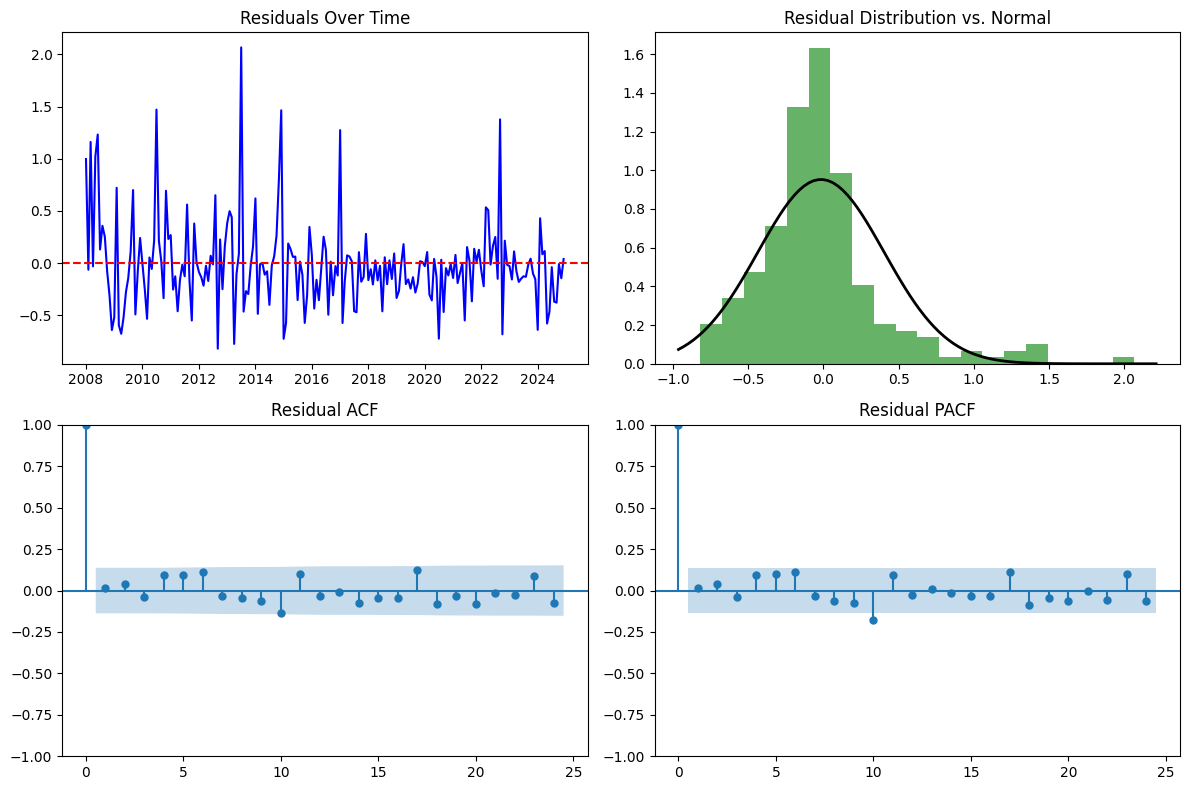


--- Running Out-of-Sample Time Series Cross-Validation ---
Training set size: 180, Testing set size: 24

Out-of-Sample Evaluation Metrics (Last 24 Months):
RMSE : 0.2650
MAE  : 0.1945


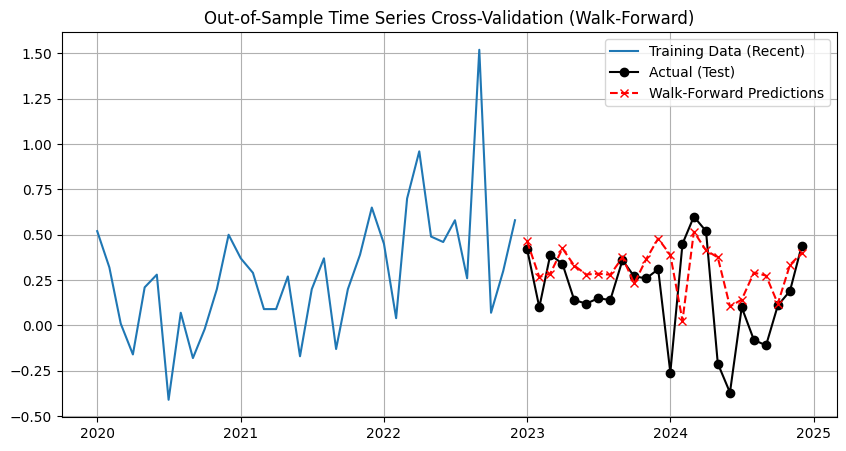

In [3]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima import auto_arima
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 0. Load & Preprocess Real Data from Excel
# ==========================================
df = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df['Tahun'] = df['Tahun'].ffill()
df['Tahun'] = pd.to_numeric(df['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan = df['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)

if bulan.isna().any():
    raise ValueError(f"Unrecognized month names: {df.loc[bulan.isna(), 'Bulan'].unique()}")

df_plot = df.copy()
df_plot['Tanggal'] = pd.to_datetime({
    'year': df_plot['Tahun'],
    'month': bulan,
    'day': 1
})
df_plot = df_plot.sort_values('Tanggal')

# Menyiapkan time series 'inflation_series' dengan index Datetime
inflation_series = (
    df_plot.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

if inflation_series.isna().any():
    raise ValueError("Kolom 'Bulanan' mengandung missing values; tangani terlebih dahulu sebelum pemodelan.")

print(f"Total observations loaded: {len(inflation_series)}")

# Plot Data Asli (Visualisasi Awal)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(inflation_series.index, inflation_series.values, marker='o', markersize=3)
ax.set_xlabel('Tahun')
ax.set_ylabel('Inflasi Bulanan (%)')
ax.set_title('Inflasi Bulanan Kota Surabaya (2008-2024)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
plt.show()

# ==========================================
# PART 1: Automated Grid Search (AIC / BIC)
# ==========================================
print("\n--- Running Auto-ARIMA Grid Search ---")

auto_model = auto_arima(
    inflation_series,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=0,             # Set 0 karena uji stasioneritas sebelumnya sudah konfirmasi stasioner
    seasonal=True,
    m=12,            # 12-month seasonality
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,          # Let auto_arima test seasonal differencing
    information_criterion='bic', # Menggunakan BIC untuk model parsimonius
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=True
)

print("\nOptimal Model Summary:")
print(auto_model.summary())

# ==========================================
# PART 2: Comprehensive Residual Diagnostics
# ==========================================
print("\n--- Running Residual Diagnostics ---")

residuals = auto_model.resid()

# 1. Ljung-Box Test untuk Autokorelasi Residual (lag 12 dan 24)
lb_test = sm.stats.acorr_ljungbox(residuals, lags=[12, 24], return_df=True)
print("\nLjung-Box Test Results:")
print(lb_test)

# 2. Normality Test (Jarque-Bera)
jb_stat, jb_pvalue = stats.jarque_bera(residuals)
print(f"\nJarque-Bera Normality Test: Stat = {jb_stat:.4f}, p-value = {jb_pvalue:.4f}")

# 3. Diagnostic Plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Standardized residuals plot
axes[0, 0].plot(residuals.index, residuals.values, color='b')
axes[0, 0].set_title("Residuals Over Time")
axes[0, 0].axhline(0, color='red', linestyle='--')

# Histogram & KDE vs Normal Distribution
axes[0, 1].hist(residuals, bins=20, density=True, alpha=0.6, color='g')
xmin, xmax = axes[0, 1].get_xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, np.mean(residuals), np.std(residuals))
axes[0, 1].plot(x, p, 'k', linewidth=2)
axes[0, 1].set_title("Residual Distribution vs. Normal")

# ACF & PACF of Residuals (Menggunakan method='yw' yang valid di statsmodels)
sm.graphics.tsa.plot_acf(residuals, lags=24, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title("Residual ACF")

sm.graphics.tsa.plot_pacf(residuals, lags=24, ax=axes[1, 1], method='yw', alpha=0.05)
axes[1, 1].set_title("Residual PACF")

plt.tight_layout()
plt.show()

# ==========================================
# PART 3: Out-of-Sample Time Series Cross-Validation
# (Walk-Forward / Rolling-Origin Validation)
# ==========================================
print("\n--- Running Out-of-Sample Time Series Cross-Validation ---")

# Menggunakan 24 bulan terakhir (2023-2024) sebagai data testing
n_test = 24
train = inflation_series.iloc[:-n_test]
test = inflation_series.iloc[-n_test:]

history = list(train)
predictions = []

print(f"Training set size: {len(train)}, Testing set size: {len(test)}")

# Walk-forward validation loop
for t in range(len(test)):
    model = pm.ARIMA(order=auto_model.order, seasonal_order=auto_model.seasonal_order)
    fitted_model = model.fit(history)
    
    # Predict 1 step ahead
    yhat = fitted_model.predict(n_periods=1)[0]
    predictions.append(yhat)
    
    # Actual observation appended to history for next step
    obs = test.iloc[t]
    history.append(obs)

predictions = pd.Series(predictions, index=test.index)

# Compute Error Metrics
rmse = root_mean_squared_error(test, predictions)
mae = mean_absolute_error(test, predictions)

print(f"\nOut-of-Sample Evaluation Metrics (Last {n_test} Months):")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")

# Plot Actual vs Predicted Out-of-Sample
plt.figure(figsize=(10, 5))
plt.plot(train.index[-36:], train.iloc[-36:], label="Training Data (Recent)")
plt.plot(test.index, test, label="Actual (Test)", color="black", marker='o')
plt.plot(predictions.index, predictions, label="Walk-Forward Predictions", color="red", linestyle='--', marker='x')
plt.title("Out-of-Sample Time Series Cross-Validation (Walk-Forward)")
plt.legend()
plt.grid(True)
plt.show()

UJI COBA SARIMAX

Total observasi y: 204, Shape exog_matrix: (204, 4)

--- Fitting Model SARIMAX dengan Faktor Eksternal ---

Ringkasan Model SARIMAX (RegARIMA):
                                     SARIMAX Results                                      
Dep. Variable:                            Bulanan   No. Observations:                  204
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood                 -94.472
Date:                            Wed, 11 Nov 2026   AIC                            206.945
Time:                                    11:10:15   BIC                            236.121
Sample:                                01-01-2008   HQIC                           218.765
                                     - 12-01-2024                                         
Covariance Type:                              opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------

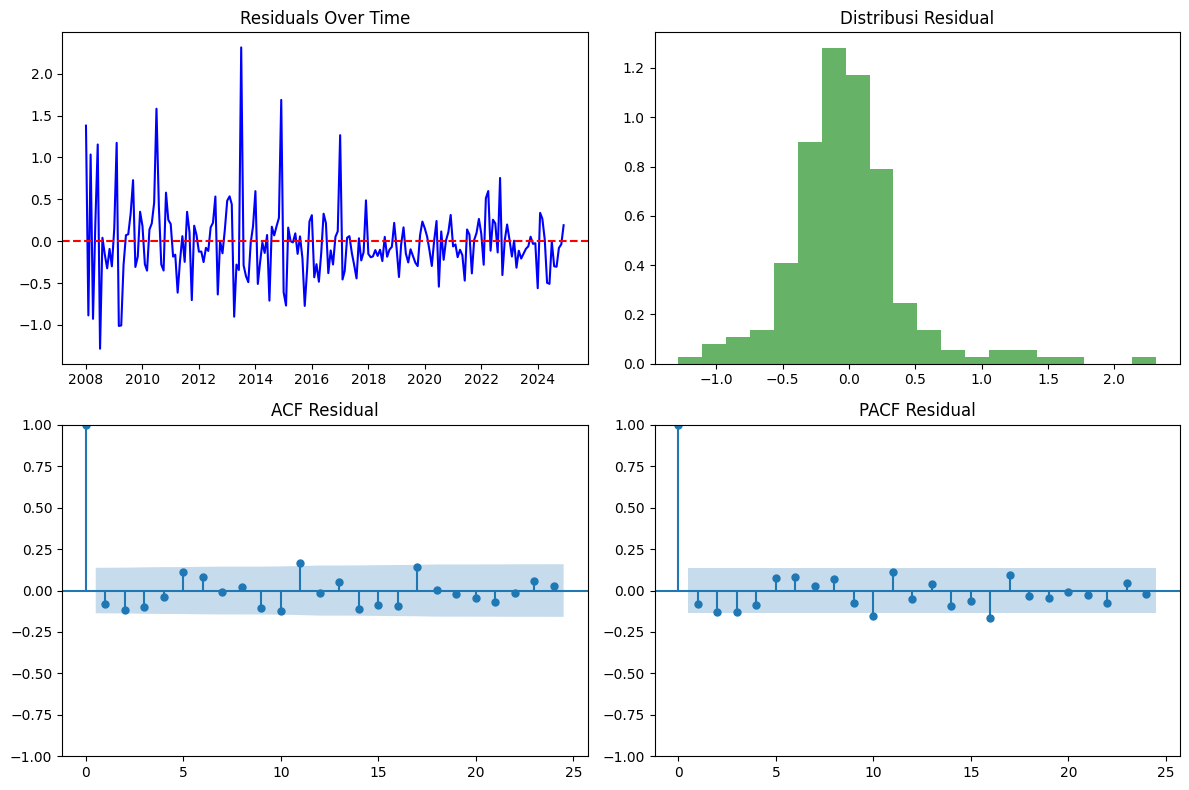


--- Menjalankan Cross-Validation Out-of-Sample ---

Evaluasi Out-of-Sample (24 Bulan Terakhir):
RMSE : 0.2632
MAE  : 0.1961


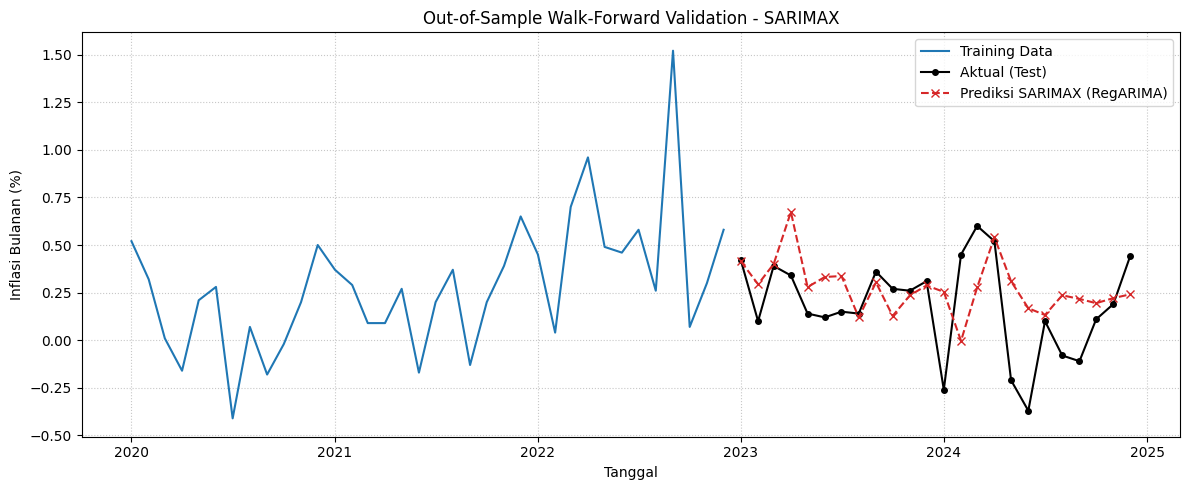

In [4]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi['Tahun'] = df_inflasi['Tahun'].ffill()
df_inflasi['Tahun'] = pd.to_numeric(df_inflasi['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)

if bulan_num.isna().any():
    raise ValueError(f"Unrecognized month names: {df_inflasi.loc[bulan_num.isna(), 'Bulan'].unique()}")

df_inflasi['Bulan_Num'] = bulan_num
df_inflasi['Tanggal'] = pd.to_datetime({
    'year': df_inflasi['Tahun'],
    'month': df_inflasi['Bulan_Num'],
    'day': 1
})
df_inflasi = df_inflasi.sort_values('Tanggal')

# ==========================================
# 2. LOAD & MERGE FAKTOR EKSTERNAL (EXOG)
# ==========================================
df_exog = pd.read_csv("faktor_eksternal_inflasi_2008_2024.csv")

# Gabungkan data inflasi dengan faktor eksternal berdasarkan Tahun & Bulan
df_combined = pd.merge(
    df_inflasi,
    df_exog[['Tahun', 'Bulan', 'Dummy_Lebaran', 'Dummy_BBM', 'Dummy_Covid', 'Dummy_ElNino']],
    left_on=['Tahun', 'Bulan_Num'],
    right_on=['Tahun', 'Bulan'],
    how='left'
)

df_combined = df_combined.sort_values('Tanggal').reset_index(drop=True)

# Definisikan Target Series (y) dan Exogenous Matrix (X)
y = df_combined.set_index('Tanggal')['Bulanan'].astype(float)
exog_matrix = df_combined[['Dummy_Lebaran', 'Dummy_BBM', 'Dummy_Covid', 'Dummy_ElNino']]
exog_matrix.index = y.index  # Menyelaraskan indeks waktu

print(f"Total observasi y: {len(y)}, Shape exog_matrix: {exog_matrix.shape}")

# ==========================================
# 3. FITTING MODEL SARIMAX (REGARIMA)
# ==========================================
print("\n--- Fitting Model SARIMAX dengan Faktor Eksternal ---")

# Gunakan order dan seasonal_order terbaik hasil pencarian sebelumnya (misal: p,d,q = 1,1,1 dan P,D,Q,s = 1,0,1,12)
p, d, q = 1, 1, 1
P, D, Q, s = 1, 0, 1, 12

sarimax_model = sm.tsa.statespace.SARIMAX(
    endog=y,
    exog=exog_matrix,
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_results = sarimax_model.fit(disp=False)

print("\nRingkasan Model SARIMAX (RegARIMA):")
print(sarimax_results.summary())

# ==========================================
# 4. DIAGNOSTIK RESIDUAL SARIMAX
# ==========================================
print("\n--- Menjalankan Diagnostik Residual ---")
residuals = sarimax_results.resid

# Uji Ljung-Box
lb_test = sm.stats.acorr_ljungbox(residuals, lags=[12, 24], return_df=True)
print("\nUji Ljung-Box Residual:")
print(lb_test)

# Plot Diagnostik
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(residuals.index, residuals.values, color='b')
axes[0, 0].set_title("Residuals Over Time")
axes[0, 0].axhline(0, color='red', linestyle='--')

axes[0, 1].hist(residuals, bins=20, density=True, alpha=0.6, color='g')
axes[0, 1].set_title("Distribusi Residual")

sm.graphics.tsa.plot_acf(residuals, lags=24, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title("ACF Residual")

sm.graphics.tsa.plot_pacf(residuals, lags=24, ax=axes[1, 1], method='yw', alpha=0.05)
axes[1, 1].set_title("PACF Residual")

plt.tight_layout()
plt.show()

# ==========================================
# 5. OUT-OF-SAMPLE WALK-FORWARD VALIDATION
# ==========================================
print("\n--- Menjalankan Cross-Validation Out-of-Sample ---")

n_test = 24  # 24 bulan terakhir (2023-2024)
y_train, y_test = y.iloc[:-n_test], y.iloc[-n_test:]
exog_train, exog_test = exog_matrix.iloc[:-n_test], exog_matrix.iloc[-n_test:]

history_y = list(y_train)
history_exog = exog_train.values.tolist()
predictions = []

for t in range(len(y_test)):
    # Fit model secara rolling dengan menyertakan exog history
    model_kf = sm.tsa.statespace.SARIMAX(
        endog=history_y,
        exog=history_exog,
        order=(p, d, q),
        seasonal_order=(P, D, Q, s),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    res_kf = model_kf.fit(disp=False)
    
    # Prediksi 1 langkah ke depan dengan memasukkan exog data testing ke-t
    current_exog = np.array([exog_test.iloc[t].values])
    yhat = res_kf.forecast(steps=1, exog=current_exog)[0]
    predictions.append(yhat)
    
    # Update history
    history_y.append(y_test.iloc[t])
    history_exog.append(exog_test.iloc[t].values)

predictions = pd.Series(predictions, index=y_test.index)

rmse = root_mean_squared_error(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)

print(f"\nEvaluasi Out-of-Sample (24 Bulan Terakhir):")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")

# Plot Prediksi vs Aktual
plt.figure(figsize=(12, 5))
plt.plot(y_train.index[-36:], y_train.iloc[-36:], label="Training Data", color='tab:blue')
plt.plot(y_test.index, y_test, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(predictions.index, predictions, label="Prediksi SARIMAX (RegARIMA)", color="tab:red", linestyle='--', marker='x')
plt.title("Out-of-Sample Walk-Forward Validation - SARIMAX")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

SARIMA

Total observations loaded: 204


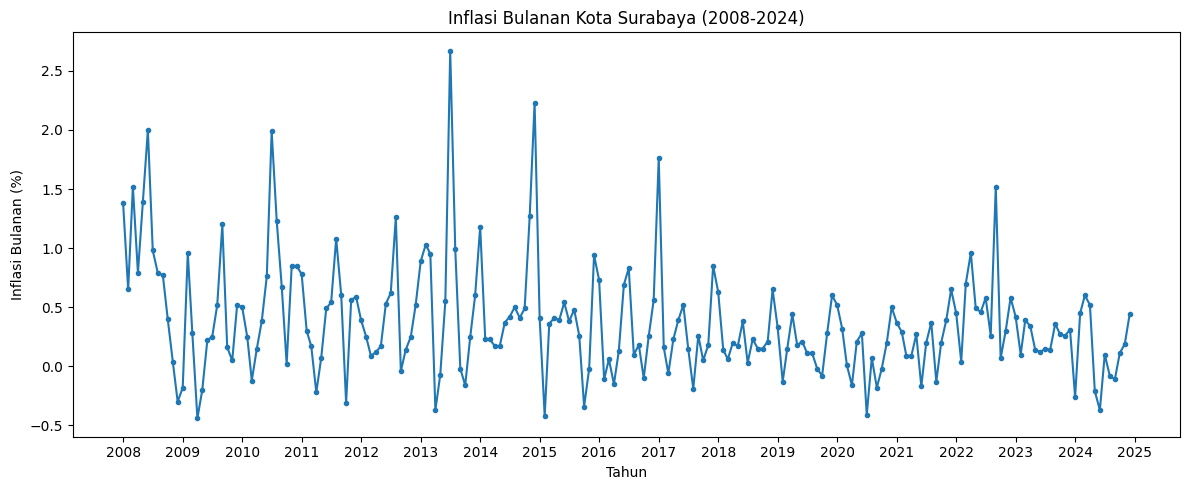


--- Running Auto-ARIMA Grid Search (SARIMA) ---
Performing stepwise search to minimize bic
 ARIMA(0,0,0)(0,0,0)[12] intercept   : BIC=282.934, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : BIC=252.970, Time=0.09 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : BIC=250.971, Time=0.07 sec
 ARIMA(0,0,0)(0,0,0)[12]             : BIC=376.548, Time=0.01 sec
 ARIMA(0,0,1)(0,0,0)[12] intercept   : BIC=250.547, Time=0.03 sec
 ARIMA(0,0,1)(1,0,0)[12] intercept   : BIC=250.578, Time=0.08 sec
 ARIMA(0,0,1)(1,0,1)[12] intercept   : BIC=248.833, Time=0.20 sec
 ARIMA(0,0,1)(2,0,1)[12] intercept   : BIC=253.800, Time=0.38 sec
 ARIMA(0,0,1)(1,0,2)[12] intercept   : BIC=253.413, Time=0.43 sec
 ARIMA(0,0,1)(0,0,2)[12] intercept   : BIC=256.289, Time=0.17 sec
 ARIMA(0,0,1)(2,0,0)[12] intercept   : BIC=254.879, Time=0.29 sec
 ARIMA(0,0,1)(2,0,2)[12] intercept   : BIC=inf, Time=0.76 sec
 ARIMA(0,0,0)(1,0,1)[12] intercept   : BIC=271.663, Time=0.13 sec
 ARIMA(1,0,1)(1,0,1)[12] intercept   : BIC=253.669, Ti

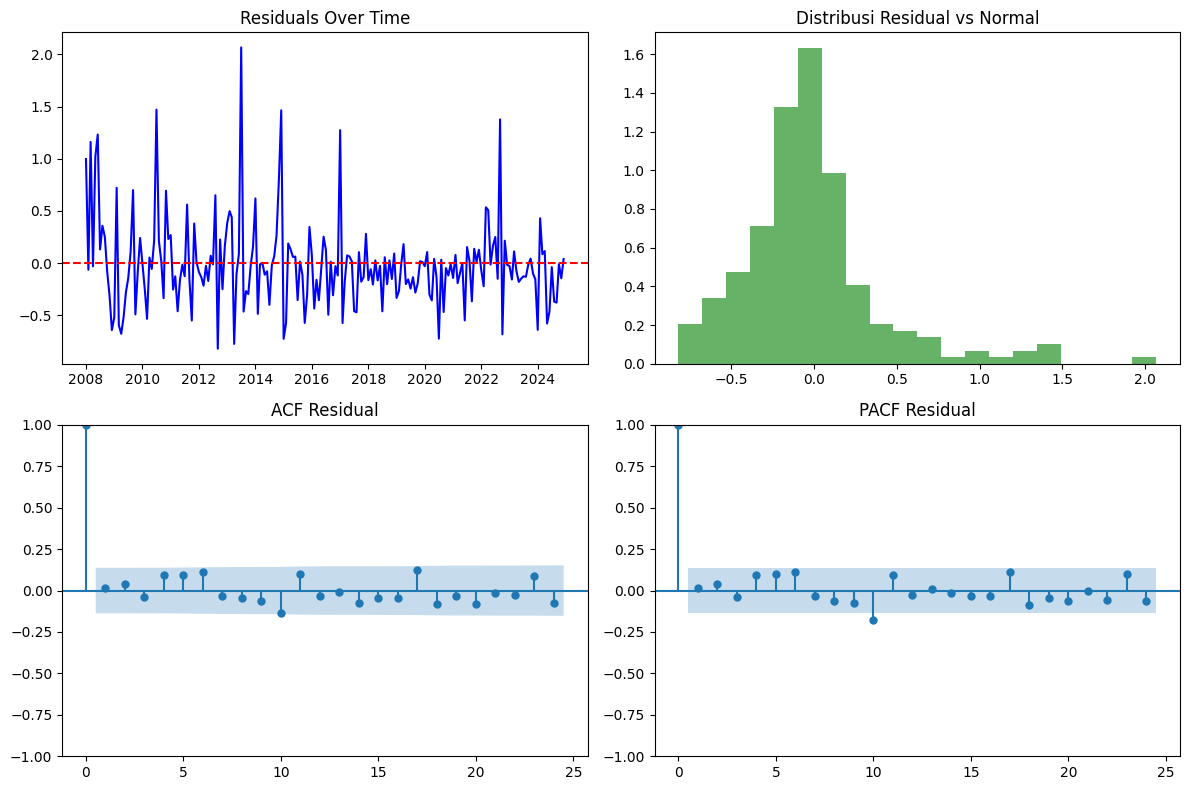


--- Menjalankan Cross-Validation Out-of-Sample (SARIMA) ---
Training set size: 180, Testing set size: 24

Evaluasi Out-of-Sample SARIMA (24 Bulan Terakhir):
RMSE : 0.2650
MAE  : 0.1945


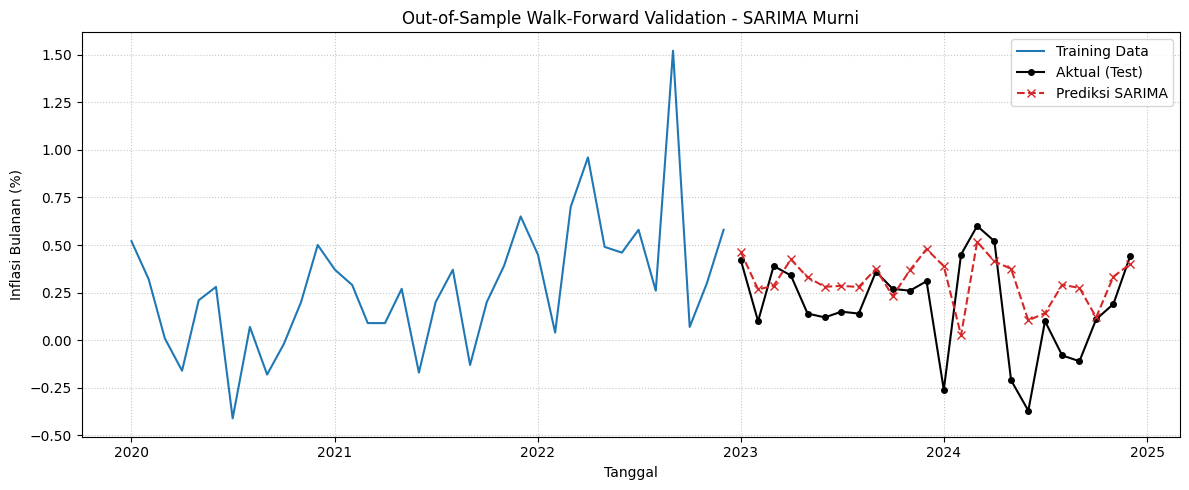

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima import auto_arima
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi['Tahun'] = df_inflasi['Tahun'].ffill()
df_inflasi['Tahun'] = pd.to_numeric(df_inflasi['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)

if bulan_num.isna().any():
    raise ValueError(f"Unrecognized month names: {df_inflasi.loc[bulan_num.isna(), 'Bulan'].unique()}")

df_inflasi['Bulan_Num'] = bulan_num
df_inflasi['Tanggal'] = pd.to_datetime({
    'year': df_inflasi['Tahun'],
    'month': df_inflasi['Bulan_Num'],
    'day': 1
})
df_inflasi = df_inflasi.sort_values('Tanggal')

# Definisikan Target Series (y)
y = (
    df_inflasi.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

print(f"Total observations loaded: {len(y)}")

# Visualisasi Data Asli
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y.index, y.values, marker='o', markersize=3, color='tab:blue')
ax.set_xlabel('Tahun')
ax.set_ylabel('Inflasi Bulanan (%)')
ax.set_title('Inflasi Bulanan Kota Surabaya (2008-2024)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
plt.show()

# ==========================================
# 2. AUTOMATED GRID SEARCH (SARIMA)
# ==========================================
print("\n--- Running Auto-ARIMA Grid Search (SARIMA) ---")

auto_model = auto_arima(
    y,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=0,             # Sesuaikan jika data membutuhkan differencing (d=1)
    seasonal=True,
    m=12,            # Musiman bulanan (12 bulan)
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,          # Let auto_arima test seasonal differencing
    information_criterion='bic', # Menggunakan BIC untuk model parsimonius
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=True
)

print("\nOptimal SARIMA Model Summary:")
print(auto_model.summary())

# ==========================================
# 3. DIAGNOSTIK RESIDUAL SARIMA
# ==========================================
print("\n--- Menjalankan Diagnostik Residual ---")
residuals = auto_model.resid()

# Uji Ljung-Box
lb_test = sm.stats.acorr_ljungbox(residuals, lags=[12, 24], return_df=True)
print("\nUji Ljung-Box Residual:")
print(lb_test)

# Uji Normalitas Jarque-Bera
jb_stat, jb_pvalue = stats.jarque_bera(residuals)
print(f"\nJarque-Bera Normality Test: Stat = {jb_stat:.4f}, p-value = {jb_pvalue:.4f}")

# Plot Diagnostik Residual
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(residuals.index, residuals.values, color='b')
axes[0, 0].set_title("Residuals Over Time")
axes[0, 0].axhline(0, color='red', linestyle='--')

axes[0, 1].hist(residuals, bins=20, density=True, alpha=0.6, color='g')
axes[0, 1].set_title("Distribusi Residual vs Normal")

sm.graphics.tsa.plot_acf(residuals, lags=24, ax=axes[1, 0], alpha=0.05)
axes[1, 0].set_title("ACF Residual")

sm.graphics.tsa.plot_pacf(residuals, lags=24, ax=axes[1, 1], method='yw', alpha=0.05)
axes[1, 1].set_title("PACF Residual")

plt.tight_layout()
plt.show()

# ==========================================
# 4. OUT-OF-SAMPLE WALK-FORWARD VALIDATION
# ==========================================
print("\n--- Menjalankan Cross-Validation Out-of-Sample (SARIMA) ---")

n_test = 24  # 24 bulan terakhir (2023-2024)
train = y.iloc[:-n_test]
test = y.iloc[-n_test:]

history = list(train)
predictions = []

print(f"Training set size: {len(train)}, Testing set size: {len(test)}")

for t in range(len(test)):
    # Fit ulang model SARIMA dengan order optimal
    model_kf = pm.ARIMA(order=auto_model.order, seasonal_order=auto_model.seasonal_order)
    fitted_model = model_kf.fit(history)
    
    # Prediksi 1 langkah ke depan
    yhat = fitted_model.predict(n_periods=1)[0]
    predictions.append(yhat)
    
    # Tambahkan nilai aktual ke history
    obs = test.iloc[t]   
    history.append(obs)

predictions = pd.Series(predictions, index=test.index)

# Hitung Metrik Evaluasi
rmse = root_mean_squared_error(test, predictions)
mae = mean_absolute_error(test, predictions)

print(f"\nEvaluasi Out-of-Sample SARIMA (24 Bulan Terakhir):")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")

# Plot Prediksi vs Aktual
plt.figure(figsize=(12, 5))
plt.plot(train.index[-36:], train.iloc[-36:], label="Training Data", color='tab:blue')
plt.plot(test.index, test, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(predictions.index, predictions, label="Prediksi SARIMA", color="tab:red", linestyle='--', marker='x')
plt.title("Out-of-Sample Walk-Forward Validation - SARIMA Murni")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

COBA SARIMA vs ETS

Training data: 180 bulan | Testing data: 24 bulan

--- Menjalankan Model SARIMA ---
--- Menjalankan Model ETS (Holt-Winters) ---

     HASIL PERBANDINGAN PERFORMA (TEST)
Model SARIMA -> RMSE: 0.2416 | MAE: 0.1799
Model ETS    -> RMSE: 0.3681 | MAE: 0.3151


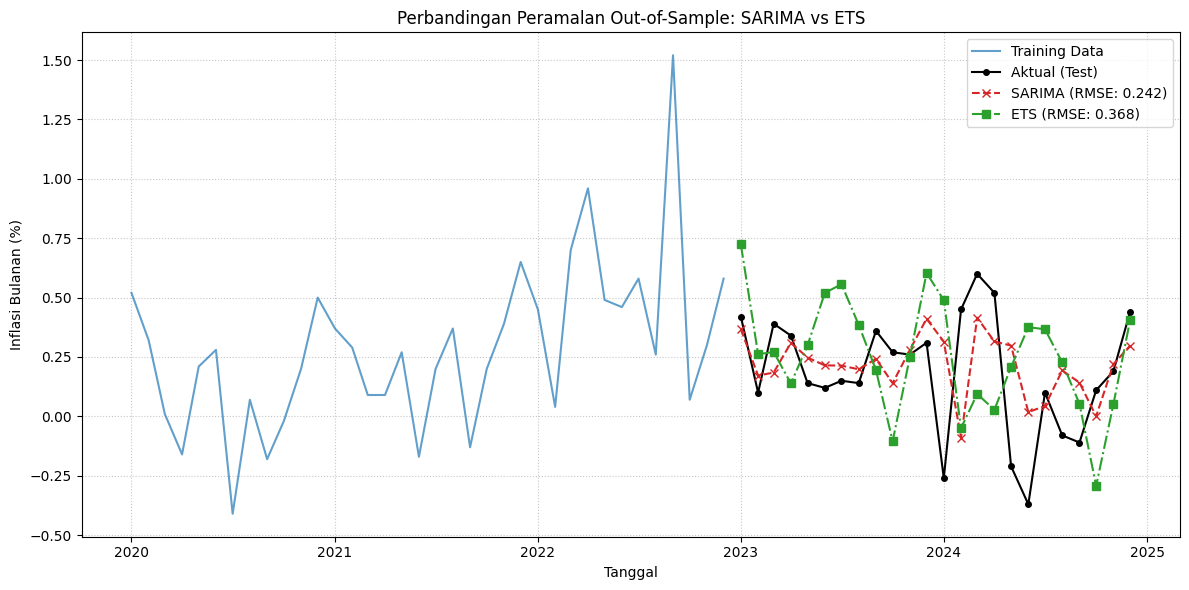

In [3]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi['Tahun'] = df_inflasi['Tahun'].ffill()
df_inflasi['Tahun'] = pd.to_numeric(df_inflasi['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)
df_inflasi['Bulan_Num'] = bulan_num
df_inflasi['Tanggal'] = pd.to_datetime({
    'year': df_inflasi['Tahun'],
    'month': df_inflasi['Bulan_Num'],
    'day': 1
})
df_inflasi = df_inflasi.sort_values('Tanggal')

y = (
    df_inflasi.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

# ==========================================
# 2. SPLIT TRAINING & TESTING (24 Bulan Terakhir)
# ==========================================
n_test = 24
train = y.iloc[:-n_test]
test = y.iloc[-n_test:]

print(f"Training data: {len(train)} bulan | Testing data: {len(test)} bulan")

# ==========================================
# 3. MODEL A: SARIMA (Walk-Forward Validation)
# ==========================================
print("\n--- Menjalankan Model SARIMA ---")
history_sarima = list(train)
pred_sarima = []

# Cari order optimal sekali di awal training untuk efisiensi
auto_model = pm.auto_arima(
    train, seasonal=True, m=12, 
    information_criterion='bic', stepwise=True, suppress_warnings=True
)
best_order = auto_model.order
best_seasonal_order = auto_model.seasonal_order

for t in range(len(test)):
    model_kf = pm.ARIMA(order=best_order, seasonal_order=best_seasonal_order)
    fitted_sarima = model_kf.fit(maxiter=200, disp=False, y=history_sarima)
    yhat = fitted_sarima.predict(n_periods=1)[0]
    pred_sarima.append(yhat)
    history_sarima.append(test.iloc[t])

pred_sarima = pd.Series(pred_sarima, index=test.index)

# ==========================================
# 4. MODEL B: ETS (Holt-Winters Exponential Smoothing)
# ==========================================
print("--- Menjalankan Model ETS (Holt-Winters) ---")
history_ets = list(train)
pred_ets = []

for t in range(len(test)):
    # Menggunakan ETS dengan tren aditif dan musiman aditif/multiplicative periode 12
    model_ets = ExponentialSmoothing(
        history_ets, 
        trend='add', 
        seasonal='add', 
        seasonal_periods=12
    ).fit()
    yhat_ets = model_ets.forecast(steps=1)[0]
    pred_ets.append(yhat_ets)
    history_ets.append(test.iloc[t])

pred_ets = pd.Series(pred_ets, index=test.index)

# ==========================================
# 5. EVALUASI & PERBANDINGAN PERFORMA
# ==========================================
rmse_sarima = root_mean_squared_error(test, pred_sarima)
mae_sarima = mean_absolute_error(test, pred_sarima)

rmse_ets = root_mean_squared_error(test, pred_ets)
mae_ets = mean_absolute_error(test, pred_ets)

print("\n==========================================")
print("     HASIL PERBANDINGAN PERFORMA (TEST)")
print("==========================================")
print(f"Model SARIMA -> RMSE: {rmse_sarima:.4f} | MAE: {mae_sarima:.4f}")
print(f"Model ETS    -> RMSE: {rmse_ets:.4f} | MAE: {mae_ets:.4f}")

# ==========================================
# 6. VISUALISASI PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train.index[-36:], train.iloc[-36:], label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test.index, test, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima.index, pred_sarima, label=f"SARIMA (RMSE: {rmse_sarima:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets.index, pred_ets, label=f"ETS (RMSE: {rmse_ets:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Peramalan Out-of-Sample: SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

Training data: 180 bulan | Testing data: 24 bulan

--- Menjalankan Model SARIMA ---


c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


--- Menjalankan Model ETS (Holt-Winters) ---

     HASIL PERBANDINGAN PERFORMA (TEST)
Model SARIMA -> RMSE: 0.2416 | MAE: 0.1799
Model ETS    -> RMSE: 0.3681 | MAE: 0.3151


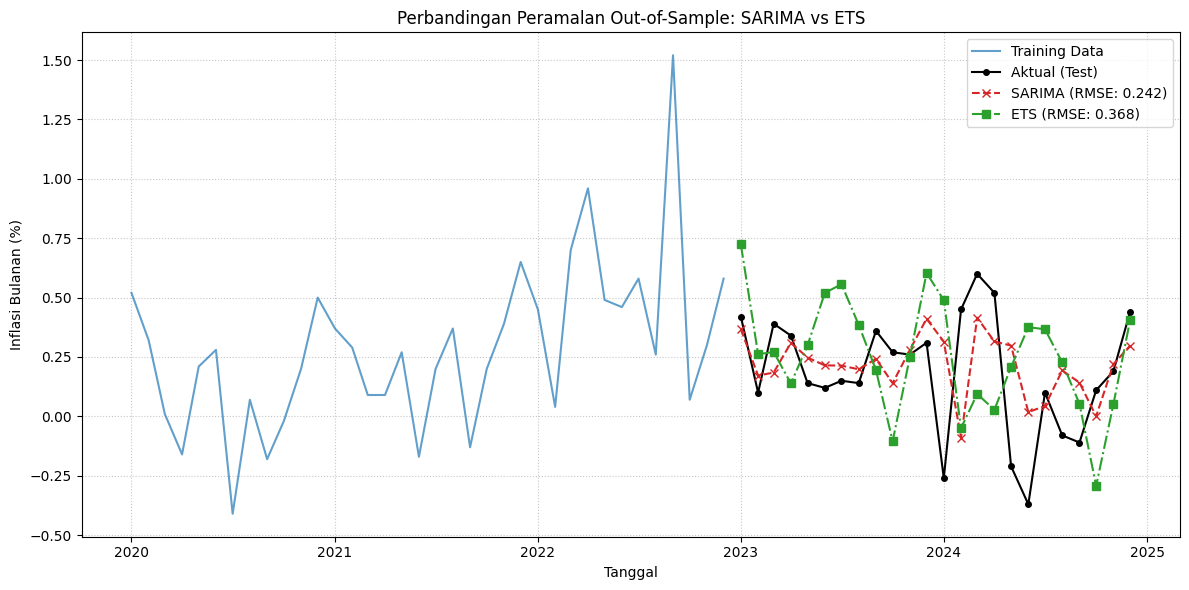

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi['Tahun'] = df_inflasi['Tahun'].ffill()
df_inflasi['Tahun'] = pd.to_numeric(df_inflasi['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)
df_inflasi['Bulan_Num'] = bulan_num
df_inflasi['Tanggal'] = pd.to_datetime({
    'year': df_inflasi['Tahun'],
    'month': df_inflasi['Bulan_Num'],
    'day': 1
})
df_inflasi = df_inflasi.sort_values('Tanggal')

y = (
    df_inflasi.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

# ==========================================
# 2. SPLIT TRAINING & TESTING (24 Bulan Terakhir)
# ==========================================
n_test = 24
train = y.iloc[:-n_test]
test = y.iloc[-n_test:]

print(f"Training data: {len(train)} bulan | Testing data: {len(test)} bulan")

# ==========================================
# 3. MODEL A: SARIMA (Walk-Forward Validation)
# ==========================================
print("\n--- Menjalankan Model SARIMA ---")
history_sarima = list(train)
pred_sarima = []

# Cari order optimal sekali di awal training untuk efisiensi
auto_model = pm.auto_arima(
    train, seasonal=True, m=12, 
    information_criterion='bic', stepwise=True, suppress_warnings=True
)
best_order = auto_model.order
best_seasonal_order = auto_model.seasonal_order

for t in range(len(test)):
    model_kf = pm.ARIMA(order=best_order, seasonal_order=best_seasonal_order)
    fitted_sarima = model_kf.fit(maxiter=200, disp=False, y=history_sarima)
    yhat = fitted_sarima.predict(n_periods=1)[0]
    pred_sarima.append(yhat)
    history_sarima.append(test.iloc[t])

pred_sarima = pd.Series(pred_sarima, index=test.index)

# ==========================================
# 4. MODEL B: ETS (Holt-Winters Exponential Smoothing)
# ==========================================
print("--- Menjalankan Model ETS (Holt-Winters) ---")
history_ets = list(train)
pred_ets = []

for t in range(len(test)):
    # Menggunakan ETS dengan tren aditif dan musiman aditif/multiplicative periode 12
    model_ets = ExponentialSmoothing(
        history_ets, 
        trend='add', 
        seasonal='add', 
        seasonal_periods=12
    ).fit()
    yhat_ets = model_ets.forecast(steps=1)[0]
    pred_ets.append(yhat_ets)
    history_ets.append(test.iloc[t])

pred_ets = pd.Series(pred_ets, index=test.index)

# ==========================================
# 5. EVALUASI & PERBANDINGAN PERFORMA
# ==========================================
rmse_sarima = root_mean_squared_error(test, pred_sarima)
mae_sarima = mean_absolute_error(test, pred_sarima)

rmse_ets = root_mean_squared_error(test, pred_ets)
mae_ets = mean_absolute_error(test, pred_ets)

print("\n==========================================")
print("     HASIL PERBANDINGAN PERFORMA (TEST)")
print("==========================================")
print(f"Model SARIMA -> RMSE: {rmse_sarima:.4f} | MAE: {mae_sarima:.4f}")
print(f"Model ETS    -> RMSE: {rmse_ets:.4f} | MAE: {mae_ets:.4f}")

# ==========================================
# 6. VISUALISASI PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train.index[-36:], train.iloc[-36:], label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test.index, test, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima.index, pred_sarima, label=f"SARIMA (RMSE: {rmse_sarima:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets.index, pred_ets, label=f"ETS (RMSE: {rmse_ets:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Peramalan Out-of-Sample: SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

In [2]:
if rmse_sarima < rmse_ets:
    print(f"SARIMA memiliki RMSE lebih rendah ({rmse_sarima:.4f} vs {rmse_ets:.4f}), sehingga lebih akurat pada periode pengujian ini.")
elif rmse_ets < rmse_sarima:
    print(f"ETS memiliki RMSE lebih rendah ({rmse_ets:.4f} vs {rmse_sarima:.4f}), sehingga lebih akurat pada periode pengujian ini.")
else:
    print(f"Kedua model memiliki RMSE yang sama ({rmse_sarima:.4f}).")

SARIMA memiliki RMSE lebih rendah (0.2416 vs 0.3681), sehingga lebih akurat pada periode pengujian ini.


c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\Sulaiman\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Long backtest: training=144 | testing=60
SARIMA -> RMSE: 0.3321 | MAE: 0.2281
ETS    -> RMSE: 0.3894 | MAE: 0.2971
SARIMA lebih akurat pada backtest yang lebih panjang.


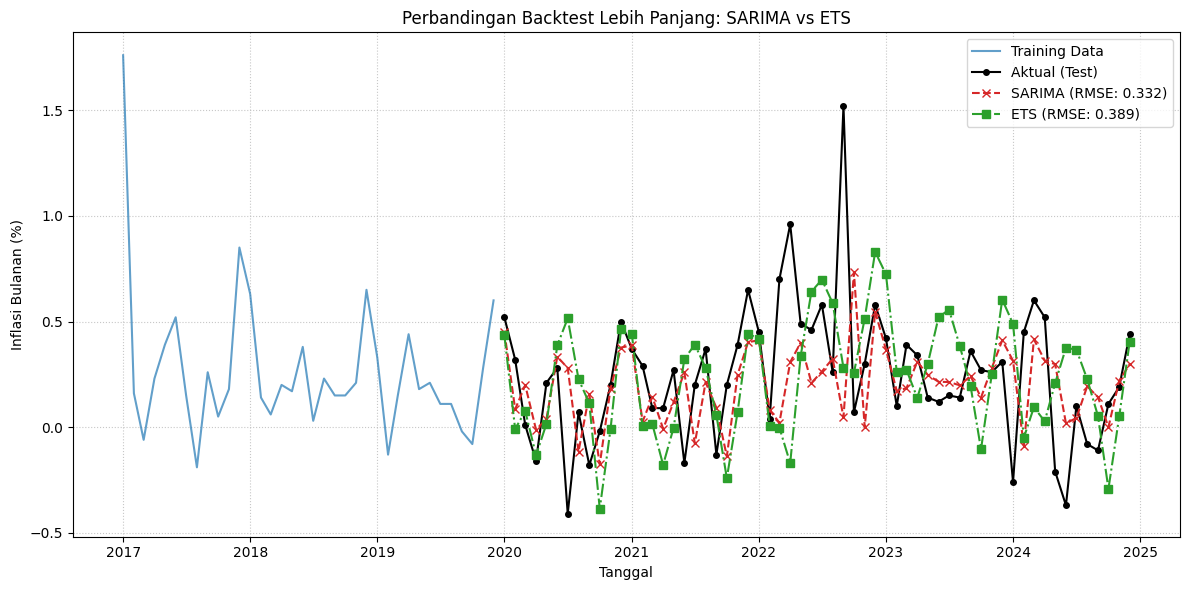

: 

In [ ]:
# Compare SARIMA vs ETS on a longer backtest window
n_test = 60
train_long = y.iloc[:-n_test]
test_long = y.iloc[-n_test:]

# SARIMA walk-forward
history_sarima = list(train_long)
pred_sarima_long = []

for t in range(len(test_long)):
    model_kf = pm.ARIMA(order=best_order, seasonal_order=best_seasonal_order)
    fitted_sarima = model_kf.fit(maxiter=200, disp=False, y=history_sarima)
    yhat = fitted_sarima.predict(n_periods=1)[0]
    pred_sarima_long.append(yhat)
    history_sarima.append(test_long.iloc[t])

pred_sarima_long = pd.Series(pred_sarima_long, index=test_long.index)

# ETS walk-forward
history_ets = list(train_long)
pred_ets_long = []

for t in range(len(test_long)):
    model_ets = ExponentialSmoothing(
        history_ets,
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()
    yhat_ets = model_ets.forecast(steps=1)[0]
    pred_ets_long.append(yhat_ets)
    history_ets.append(test_long.iloc[t])

pred_ets_long = pd.Series(pred_ets_long, index=test_long.index)

# Metrics
rmse_sarima_long = root_mean_squared_error(test_long, pred_sarima_long)
mae_sarima_long = mean_absolute_error(test_long, pred_sarima_long)

rmse_ets_long = root_mean_squared_error(test_long, pred_ets_long)
mae_ets_long = mean_absolute_error(test_long, pred_ets_long)

print(f"Long backtest: training={len(train_long)} | testing={len(test_long)}")
print(f"SARIMA -> RMSE: {rmse_sarima_long:.4f} | MAE: {mae_sarima_long:.4f}")
print(f"ETS    -> RMSE: {rmse_ets_long:.4f} | MAE: {mae_ets_long:.4f}")

if rmse_sarima_long < rmse_ets_long:
    print("SARIMA lebih akurat pada backtest yang lebih panjang.")
elif rmse_ets_long < rmse_sarima_long:
    print("ETS lebih akurat pada backtest yang lebih panjang.")
else:
    print("Keduanya setara pada backtest yang lebih panjang.")

# Plot comparison
plt.figure(figsize=(12, 6))
plt.plot(train_long.index[-36:], train_long.iloc[-36:], label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long.index, test_long, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')
plt.title("Perbandingan Backtest Lebih Panjang: SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

Long backtest: training=144 | testing=60

--- Mencari Order Optimal SARIMA pada Data Training ---
Order terbaik ditemukan: SARIMA (0, 0, 1) x (0, 0, 0, 12)

Menjalankan Walk-Forward SARIMA (60 bulan)...
Menjalankan Walk-Forward ETS (60 bulan)...

   HASIL EVALUASI BACKTEST 60 BULAN
SARIMA -> RMSE: 0.3360 | MAE: 0.2377
ETS    -> RMSE: 0.3894 | MAE: 0.2971

Kesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.


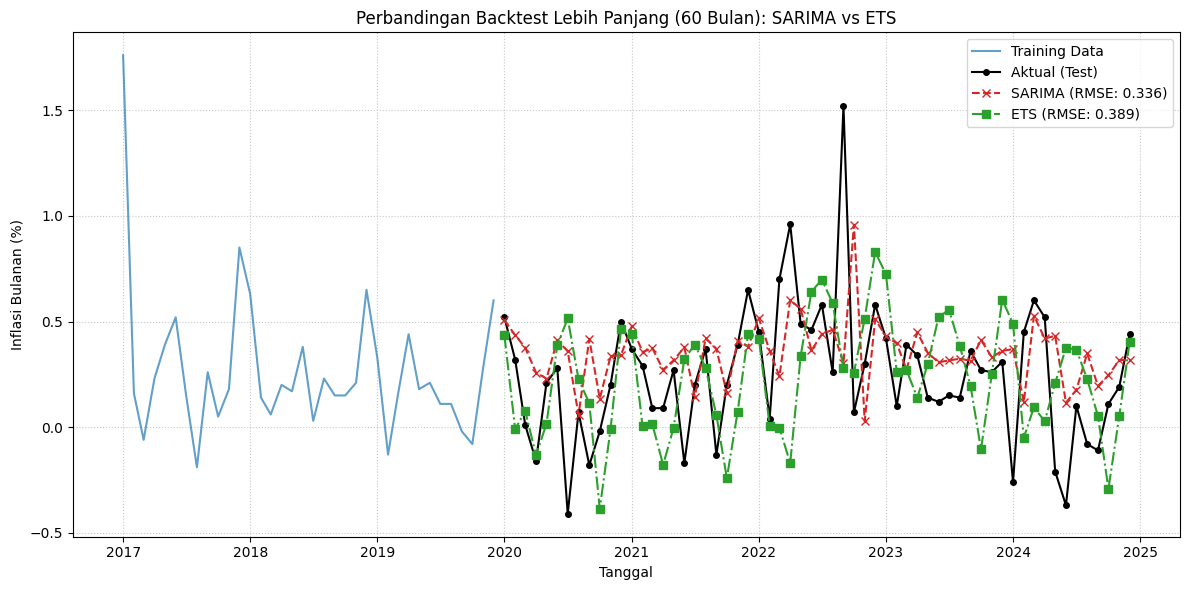

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi['Tahun'] = df_inflasi['Tahun'].ffill()
df_inflasi['Tahun'] = pd.to_numeric(df_inflasi['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)
df_inflasi['Bulan_Num'] = bulan_num
df_inflasi['Tanggal'] = pd.to_datetime({
    'year': df_inflasi['Tahun'],
    'month': df_inflasi['Bulan_Num'],
    'day': 1
})
df_inflasi = df_inflasi.sort_values('Tanggal')

y = (
    df_inflasi.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

# ==========================================
# 2. SPLIT TRAINING & TESTING (Long Backtest)
# ==========================================
n_test = 60  # 60 bulan terakhir (5 tahun)
train_long = y.iloc[:-n_test]
test_long = y.iloc[-n_test:]

print(f"Long backtest: training={len(train_long)} | testing={len(test_long)}")

# ==========================================
# 3. AUTO-ARIMA UNTUK MENDAPATKAN BEST ORDER
# ==========================================
print("\n--- Mencari Order Optimal SARIMA pada Data Training ---")
auto_model = auto_arima(
    train_long,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=0,
    seasonal=True,
    m=12,
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion='bic',
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=False
)

best_order = auto_model.order
best_seasonal_order = auto_model.seasonal_order
print(f"Order terbaik ditemukan: SARIMA {best_order} x {best_seasonal_order}")

# ==========================================
# 4. SARIMA WALK-FORWARD VALIDATION
# ==========================================
history_sarima = list(train_long)
pred_sarima_long = []

print("\nMenjalankan Walk-Forward SARIMA (60 bulan)...")
for t in range(len(test_long)):
    model_kf = pm.ARIMA(order=best_order, seasonal_order=best_seasonal_order)
    fitted_sarima = model_kf.fit(history_sarima, maxiter=200, disp=False)
    yhat = fitted_sarima.predict(n_periods=1)[0]
    pred_sarima_long.append(yhat)
    history_sarima.append(test_long.iloc[t])

pred_sarima_long = pd.Series(pred_sarima_long, index=test_long.index)

# ==========================================
# 5. ETS WALK-FORWARD VALIDATION
# ==========================================
history_ets = list(train_long)
pred_ets_long = []

print("Menjalankan Walk-Forward ETS (60 bulan)...")
for t in range(len(test_long)):
    model_ets = ExponentialSmoothing(
        history_ets,
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()
    yhat_ets = model_ets.forecast(steps=1)[0]
    pred_ets_long.append(yhat_ets)
    history_ets.append(test_long.iloc[t])

pred_ets_long = pd.Series(pred_ets_long, index=test_long.index)

# ==========================================
# 6. EVALUASI & METRIK PERBANDINGAN
# ==========================================
rmse_sarima_long = root_mean_squared_error(test_long, pred_sarima_long)
mae_sarima_long = mean_absolute_error(test_long, pred_sarima_long)

rmse_ets_long = root_mean_squared_error(test_long, pred_ets_long)
mae_ets_long = mean_absolute_error(test_long, pred_ets_long)

print("\n==========================================")
print("   HASIL EVALUASI BACKTEST 60 BULAN")
print("==========================================")
print(f"SARIMA -> RMSE: {rmse_sarima_long:.4f} | MAE: {mae_sarima_long:.4f}")
print(f"ETS    -> RMSE: {rmse_ets_long:.4f} | MAE: {mae_ets_long:.4f}")

if rmse_sarima_long < rmse_ets_long:
    print("\nKesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.")
elif rmse_ets_long < rmse_sarima_long:
    print("\nKesimpulan: ETS lebih akurat pada backtest yang lebih panjang.")
else:
    print("\nKesimpulan: Keduanya setara pada backtest yang lebih panjang.")

# ==========================================
# 7. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train_long.index[-36:], train_long.iloc[-36:], label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long.index, test_long, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

# Uji stasioneritas pada data training (tidak menggunakan data test)
diagnosa_konflik(train_long, 'Data Training')

# PENGUJIAN SARIMA vs ETS

### Pengujian SARIMA vs ETS (Menggunakan difference auto/d=None)

Long backtest: training=144 | testing=60

--- Mencari Order Optimal SARIMA pada Data Training ---
Order terbaik ditemukan: SARIMA (0, 1, 2) x (1, 0, 1, 12)

Menjalankan Walk-Forward SARIMA (60 bulan)...
Menjalankan Walk-Forward ETS (60 bulan)...

   HASIL EVALUASI BACKTEST 60 BULAN
SARIMA -> RMSE: 0.3321 | MAE: 0.2281
ETS    -> RMSE: 0.3894 | MAE: 0.2971

Kesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.


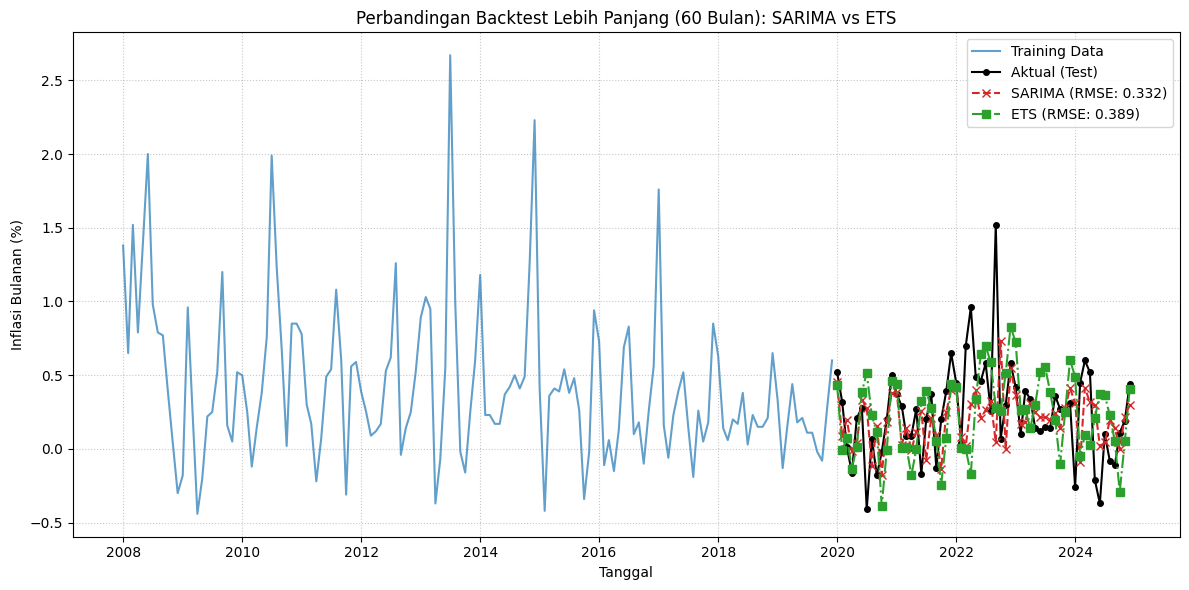

In [2]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi2 = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi2['Tahun'] = df_inflasi2['Tahun'].ffill()
df_inflasi2['Tahun'] = pd.to_numeric(df_inflasi2['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi2['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)
df_inflasi2['Bulan_Num'] = bulan_num
df_inflasi2['Tanggal'] = pd.to_datetime({
    'year': df_inflasi2['Tahun'],
    'month': df_inflasi2['Bulan_Num'],
    'day': 1
})
df_inflasi2 = df_inflasi2.sort_values('Tanggal')

y = (
    df_inflasi2.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

# ==========================================
# 2. SPLIT TRAINING & TESTING (Long Backtest)
# ==========================================
n_test = 60  # 60 bulan terakhir (5 tahun)
train_long = y.iloc[:-n_test]
test_long = y.iloc[-n_test:]

print(f"Long backtest: training={len(train_long)} | testing={len(test_long)}")

# ==========================================
# 3. AUTO-ARIMA UNTUK MENDAPATKAN BEST ORDER
# ==========================================
print("\n--- Mencari Order Optimal SARIMA pada Data Training ---")
auto_model = auto_arima(
    train_long,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,
    seasonal=True,
    m=12,
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion='bic',
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=False
)

best_order = auto_model.order
best_seasonal_order = auto_model.seasonal_order
print(f"Order terbaik ditemukan: SARIMA {best_order} x {best_seasonal_order}")

# ==========================================
# 4. SARIMA WALK-FORWARD VALIDATION
# ==========================================
history_sarima = list(train_long)
pred_sarima_long = []

print("\nMenjalankan Walk-Forward SARIMA (60 bulan)...")
for t in range(len(test_long)):
    model_kf = pm.ARIMA(order=best_order, seasonal_order=best_seasonal_order)
    fitted_sarima = model_kf.fit(history_sarima, maxiter=200, disp=False)
    yhat = fitted_sarima.predict(n_periods=1)[0]
    pred_sarima_long.append(yhat)
    history_sarima.append(test_long.iloc[t])

pred_sarima_long = pd.Series(pred_sarima_long, index=test_long.index)

# ==========================================
# 5. ETS WALK-FORWARD VALIDATION
# ==========================================
history_ets = list(train_long)
pred_ets_long = []

print("Menjalankan Walk-Forward ETS (60 bulan)...")
for t in range(len(test_long)):
    model_ets = ExponentialSmoothing(
        history_ets,
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()
    yhat_ets = model_ets.forecast(steps=1)[0]
    pred_ets_long.append(yhat_ets)
    history_ets.append(test_long.iloc[t])

pred_ets_long = pd.Series(pred_ets_long, index=test_long.index)

# ==========================================
# 6. EVALUASI & METRIK PERBANDINGAN
# ==========================================
rmse_sarima_long = root_mean_squared_error(test_long, pred_sarima_long)
mae_sarima_long = mean_absolute_error(test_long, pred_sarima_long)

rmse_ets_long = root_mean_squared_error(test_long, pred_ets_long)
mae_ets_long = mean_absolute_error(test_long, pred_ets_long)

print("\n==========================================")
print("   HASIL EVALUASI BACKTEST 60 BULAN")
print("==========================================")
print(f"SARIMA -> RMSE: {rmse_sarima_long:.4f} | MAE: {mae_sarima_long:.4f}")
print(f"ETS    -> RMSE: {rmse_ets_long:.4f} | MAE: {mae_ets_long:.4f}")

if rmse_sarima_long < rmse_ets_long:
    print("\nKesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.")
elif rmse_ets_long < rmse_sarima_long:
    print("\nKesimpulan: ETS lebih akurat pada backtest yang lebih panjang.")
else:
    print("\nKesimpulan: Keduanya setara pada backtest yang lebih panjang.")

# ==========================================
# 7. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
# Menampilkan seluruh data training tanpa dibatasi [-36:]
plt.plot(train_long.index, train_long, label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long.index, test_long, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Visualisasi Tahun yang Diprediksi

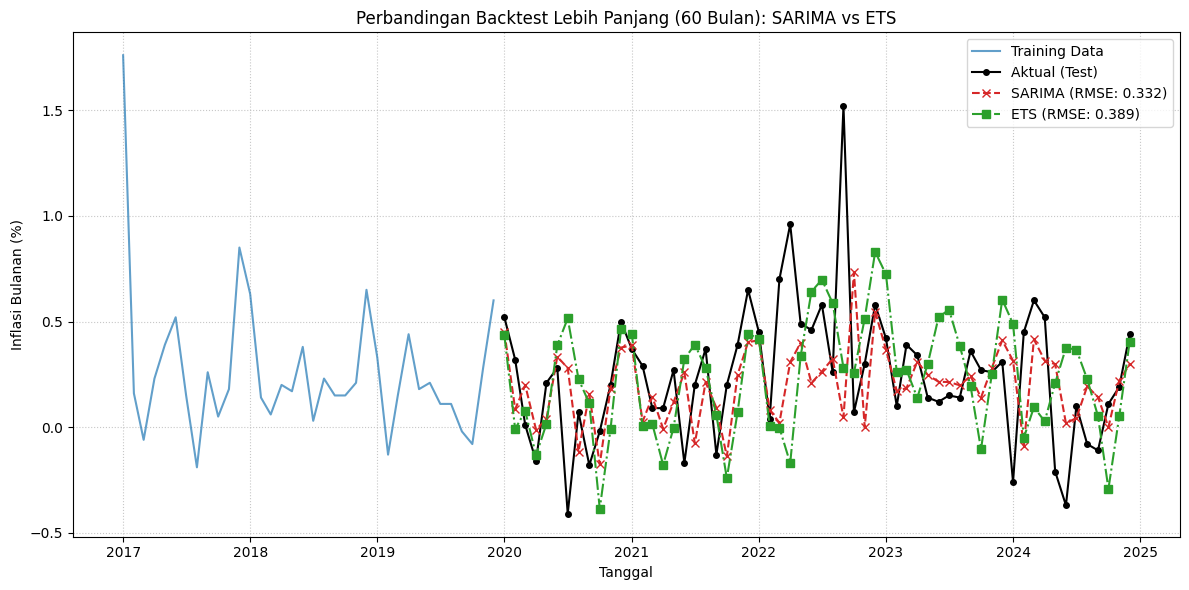

In [3]:
# ==========================================
# 7. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train_long.index[-36:], train_long.iloc[-36:], label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long.index, test_long, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Pengujian SARIMA vs ETS (Menggunakan difference 0/d=0)

Long backtest: training=144 | testing=60

--- Uji Stasioneritas ADF pada Data Training ---
ADF Statistic : -4.7306
p-value       : 0.0001
Kesimpulan: Data training stasioner (Valid menggunakan d=0)

--- Mencari Order Optimal SARIMA pada Data Training ---
Order terbaik ditemukan: SARIMA (0, 0, 1) x (0, 0, 0, 12)

Menjalankan Walk-Forward SARIMA (60 bulan)...
Menjalankan Walk-Forward ETS (60 bulan)...

    HASIL EVALUASI BACKTEST 60 BULAN
SARIMA -> RMSE: 0.3360 | MAE: 0.2377
ETS    -> RMSE: 0.3894 | MAE: 0.2971

Kesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.


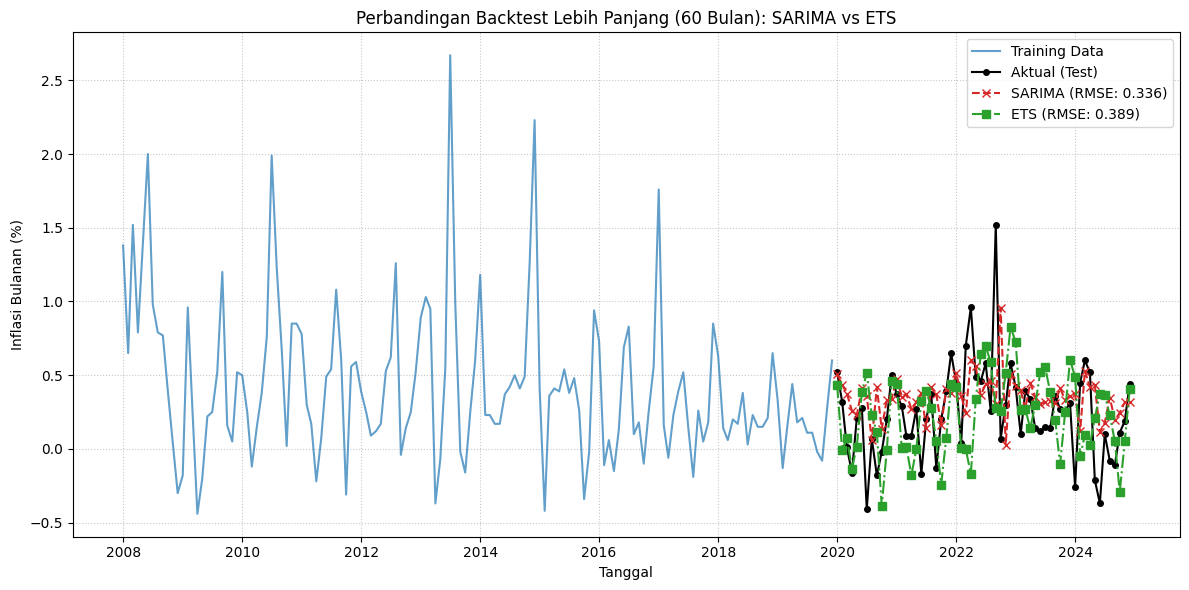

In [4]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import pmdarima as pm
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==========================================
# 1. LOAD & PREPROCESS DATA INFLASI
# ==========================================
df_inflasi = pd.read_excel(r"C:\KULIAH\UPN\TUGAS WOK\Semester 5 bos\ADW\Inflasi Kota Surabaya Tahun 2008-2024.xlsx")

df_inflasi['Tahun'] = df_inflasi['Tahun'].ffill()
df_inflasi['Tahun'] = pd.to_numeric(df_inflasi['Tahun'], errors='raise').astype(int)

bulan_ke = {
    'januari': 1, 'februari': 2, 'maret': 3, 'april': 4,
    'mei': 5, 'juni': 6, 'juli': 7, 'agustus': 8,
    'september': 9, 'oktober': 10, 'november': 11, 'desember': 12
}

bulan_num = df_inflasi['Bulan'].astype(str).str.strip().str.lower().map(bulan_ke)
df_inflasi['Bulan_Num'] = bulan_num
df_inflasi['Tanggal'] = pd.to_datetime({
    'year': df_inflasi['Tahun'],
    'month': df_inflasi['Bulan_Num'],
    'day': 1
})
df_inflasi = df_inflasi.sort_values('Tanggal')

y = (
    df_inflasi.sort_values('Tanggal')
    .set_index('Tanggal')['Bulanan']
    .astype(float)
)

# ==========================================
# 2. SPLIT TRAINING & TESTING (Long Backtest)
# ==========================================
n_test2 = 60  # 60 bulan terakhir (5 tahun)
train_long2 = y.iloc[:-n_test2]
test_long2 = y.iloc[-n_test2:]

print(f"Long backtest: training={len(train_long2)} | testing={len(test_long2)}")

# ==========================================
# 3. UJI STASIONERITAS (ADF TEST) UNTUK VALIDASI d=0
# ==========================================
print("\n--- Uji Stasioneritas ADF pada Data Training ---")
adf_result = adfuller(train_long2.dropna())
print(f"ADF Statistic : {adf_result[0]:.4f}")
print(f"p-value       : {adf_result[1]:.4f}")

if adf_result[1] < 0.05:
    print("Kesimpulan: Data training stasioner (Valid menggunakan d=0)")
else:
    print("Kesimpulan: Data training tidak stasioner (Pertimbangkan d=None atau d=1)")

# ==========================================
# 4. AUTO-ARIMA UNTUK MENDAPATKAN BEST ORDER
# ==========================================
print("\n--- Mencari Order Optimal SARIMA pada Data Training ---")
auto_model = auto_arima(
    train_long2,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=0,             # Hasil ADF menunjukkan data stasioner, sehingga d=0
    seasonal=True,
    m=12,
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion='bic',
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=False
)

best_order = auto_model.order
best_seasonal_order = auto_model.seasonal_order
print(f"Order terbaik ditemukan: SARIMA {best_order} x {best_seasonal_order}")

# ==========================================
# 5. SARIMA WALK-FORWARD VALIDATION
# ==========================================
history_sarima = list(train_long)
pred_sarima_long = []

print("\nMenjalankan Walk-Forward SARIMA (60 bulan)...")
for t in range(len(test_long)):
    model_kf = pm.ARIMA(order=best_order, seasonal_order=best_seasonal_order)
    fitted_sarima = model_kf.fit(history_sarima, maxiter=200, disp=False)
    yhat = fitted_sarima.predict(n_periods=1)[0]
    pred_sarima_long.append(yhat)
    history_sarima.append(test_long.iloc[t])

pred_sarima_long = pd.Series(pred_sarima_long, index=test_long.index)

# ==========================================
# 6. ETS WALK-FORWARD VALIDATION
# ==========================================
history_ets = list(train_long)
pred_ets_long = []

print("Menjalankan Walk-Forward ETS (60 bulan)...")
for t in range(len(test_long)):
    model_ets = ExponentialSmoothing(
        history_ets,
        trend='add',
        seasonal='add',
        seasonal_periods=12
    ).fit()
    yhat_ets = model_ets.forecast(steps=1)[0]
    pred_ets_long.append(yhat_ets)
    history_ets.append(test_long.iloc[t])

pred_ets_long = pd.Series(pred_ets_long, index=test_long.index)

# ==========================================
# 7. EVALUASI & METRIK PERBANDINGAN
# ==========================================
rmse_sarima_long = root_mean_squared_error(test_long, pred_sarima_long)
mae_sarima_long = mean_absolute_error(test_long, pred_sarima_long)

rmse_ets_long = root_mean_squared_error(test_long, pred_ets_long)
mae_ets_long = mean_absolute_error(test_long, pred_ets_long)

print("\n==========================================")
print("    HASIL EVALUASI BACKTEST 60 BULAN")
print("==========================================")
print(f"SARIMA -> RMSE: {rmse_sarima_long:.4f} | MAE: {mae_sarima_long:.4f}")
print(f"ETS    -> RMSE: {rmse_ets_long:.4f} | MAE: {mae_ets_long:.4f}")

if rmse_sarima_long < rmse_ets_long:
    print("\nKesimpulan: SARIMA lebih akurat pada backtest yang lebih panjang.")
elif rmse_ets_long < rmse_sarima_long:
    print("\nKesimpulan: ETS lebih akurat pada backtest yang lebih panjang.")
else:
    print("\nKesimpulan: Keduanya setara pada backtest yang lebih panjang.")

# ==========================================
# 8. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train_long.index, train_long, label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long.index, test_long, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

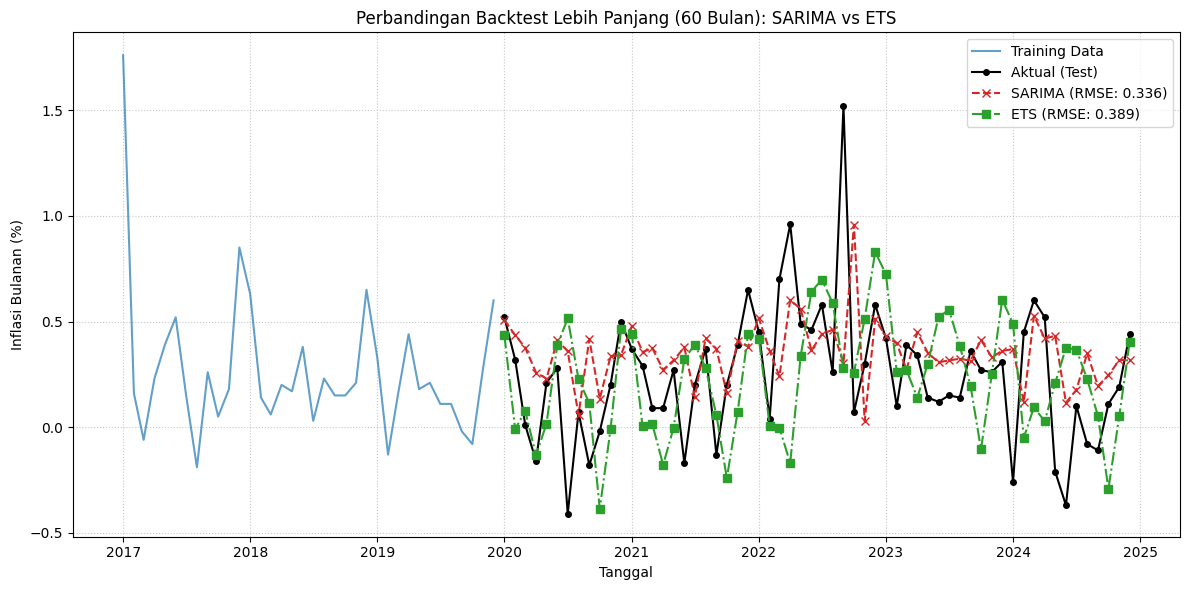

In [5]:
# ==========================================
# 7. VISUALISASI HASIL PERBANDINGAN
# ==========================================
plt.figure(figsize=(12, 6))
plt.plot(train_long2.index[-36:], train_long2.iloc[-36:], label="Training Data", color='tab:blue', alpha=0.7)
plt.plot(test_long2.index, test_long2, label="Aktual (Test)", color="black", marker='o', markersize=4)
plt.plot(pred_sarima_long.index, pred_sarima_long, label=f"SARIMA (RMSE: {rmse_sarima_long:.3f})", color="tab:red", linestyle='--', marker='x')
plt.plot(pred_ets_long.index, pred_ets_long, label=f"ETS (RMSE: {rmse_ets_long:.3f})", color="tab:green", linestyle='-.', marker='s')

plt.title("Perbandingan Backtest Lebih Panjang (60 Bulan): SARIMA vs ETS")
plt.xlabel("Tanggal")
plt.ylabel("Inflasi Bulanan (%)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

Dalam dua jenis pengujian ini saya menggunakan dua jenis "Degree of Differencing" / d yang berbeda. Dimana pada 'Pengujian SARIMA vs ETS (Menggunakan difference 0/d=0)', berdasarkan uji stationeritas ADF menunjukkan data bersifat stationer sehingga d=0. Sedangkan pada 'Pengujian SARIMA vs ETS (Menggunakan difference auto/d=None)', berdasarkan uji stationeritas yang dilakukan otomatis oleh logika 'auto_arima' dimana mencari yang terbaik dari beberapa uji seperti KPSS, ADF, dan PP menujukkan data bersifat tidak stationer dengan d=1.   

Karena pada 'Pengujian SARIMA vs ETS (Menggunakan difference auto/d=None)' menghasilkan 'rmse' SARIMA dengan nilai yang lebih kecil dari 'rmse' SARIMA pada 'Pengujian SARIMA vs ETS (Menggunakan difference 0/d=0)', saya menggunakan uji perbandingan pada 'Pengujian SARIMA vs ETS (Menggunakan difference auto/d=None)' dengan nilai rmse sarima sebesar 0.3321 dan 0.3360 berurutan.